# Inspecting `vgrid_rolling_ridge_exog_7d` — the original Ridge-retrieval champion

Headline: HC-MAE = **123.41**, Δ vs lag-7 baseline = **−25.56** (capture 21.1 % of the v_grid bucket-oracle gap), win-rate **60.3 %** on n=17 232 demand auctions (2024-05 → 2025-04).

This model is a per-interval rolling Ridge regression on the v_grid demand embedding, with monthly refit, lag-7 cutoff, and `MarketStateProxySource(lag_days=7)` + synthetic-weather exog. The Ridge predicts a 64-d v_grid embedding for the target auction, then **retrieves the nearest real historical curve** from the same `(interval, dow)` bucket as the prediction. Output is a *real* step curve from the training library.

This notebook does an exhaustive residual analysis of the Ridge retrieval:

1. **Load & score** — champion + lag-7 baseline predictions, per-row HC-MAE
2. **HC-MAE distribution** — histograms, CDF, quantiles, scatter
3. **Per-row Δ** — distribution, cumulative gain over baseline
4. **Time series** — daily aggregates over the 12-month test window
5. **Per-interval / per-weekday / heatmap** — where the model helps
6. **Per-month detail** — mean, median, IQR, win-rate, boxplot
7. **Covariate correlation** — Spearman ρ of HC-MAE / Δ vs baseline-difficulty, weekday, interval, total quantity, retrieval distance, retrieved age
8. **Difficulty stratification** — deciles by baseline HC-MAE
9. **Per-volume residual / bias** — mean signed & absolute residual `(true − pred)` along the volume axis
10. **Per-quantile residual** — bias inside 5 volume bands `[0, .2, .4, .6, .8, 1.0]` of V_max
11. **Retrieved-date analysis** — how recent are the picked candidates, do older retrievals do worse?
12. **Example curves** — one random sample per 5%-percentile of champion HC-MAE
13. **Example curves 2D** — 5×5 grid by (Δ HC-MAE quintile × champion HC-MAE quintile)
14. **Example curves 2D with residual strips** — 5×5 grid + per-V |residual| visible
15. **Outlier digging** — top-20 worst rows: are they concentrated by date / interval / month?
16. **Numerical summary**

## 1. Load & score

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from joblib import Parallel, delayed
from scipy.stats import spearmanr

from aemo_curves.metrics.hc_mae import curve_hc_mae_distance, _step_eval

plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3

REPO = Path('..').resolve()
MLRUNS = REPO / 'mlruns'

CHAMPION = 'vgrid_d7d__rolling_ridge_exog'
BASELINE = '7d__baseline_lag7_demand'


def find_run(name):
    for t in MLRUNS.glob('*/*/tags/experiment_name'):
        if t.read_text().strip() == name:
            return t.parent.parent
    raise FileNotFoundError(name)


def load(name):
    df = pd.read_pickle(find_run(name) / 'artifacts' / 'result' / 'predictions.pkl')
    df['Trading Date'] = pd.to_datetime(df['Trading Date'])
    return df


champion = load(CHAMPION)
base = load(BASELINE)
print(f'champion ({CHAMPION}): {len(champion):,} rows  ·  columns: {list(champion.columns)[:6]}...')
print(f'baseline ({BASELINE}): {len(base):,} rows')

champion (vgrid_d7d__rolling_ridge_exog): 17,232 rows  ·  columns: ['Trading Date', 'Interval Number', 'true_embedding', 'pred_embedding', 'true_curve_qty', 'true_curve_price']...
baseline (7d__baseline_lag7_demand): 17,232 rows


In [2]:
def _row(args):
    return curve_hc_mae_distance(args[0], args[1], args[2], args[3])


def score(df, label):
    args = list(zip(df['true_curve_qty'], df['true_curve_price'],
                    df['pred_curve_qty'], df['pred_curve_price']))
    df['hc_mae'] = Parallel(n_jobs=-1)(delayed(_row)(a) for a in args)
    print(f'{label:>10s}: HC-MAE mean={df["hc_mae"].mean():.2f}  median={df["hc_mae"].median():.2f}  p95={df["hc_mae"].quantile(0.95):.2f}')


score(champion, 'champion')
score(base, 'baseline')

key = ['Trading Date', 'Interval Number']
m = champion.merge(
    base[key + ['hc_mae', 'pred_curve_qty', 'pred_curve_price']].rename(columns={
        'hc_mae': 'baseline_hc_mae',
        'pred_curve_qty': 'base_curve_qty',
        'pred_curve_price': 'base_curve_price',
    }),
    on=key, how='inner',
)
m['delta_hc'] = m['hc_mae'] - m['baseline_hc_mae']
m['win'] = m['delta_hc'] < 0
m['dow'] = m['Trading Date'].dt.dayofweek
m['month'] = m['Trading Date'].dt.to_period('M').astype(str)
m['true_total_mw'] = m['true_curve_qty'].apply(lambda q: float(np.asarray(q)[-1]))
m['pred_total_mw'] = m['pred_curve_qty'].apply(lambda q: float(np.asarray(q)[-1]))
m['vmax_mismatch'] = m['pred_total_mw'] - m['true_total_mw']
if 'retrieved_date' in m.columns:
    m['retrieved_age_days'] = (m['Trading Date'] - pd.to_datetime(m['retrieved_date'])).dt.days
print(f'\nmerged: {len(m):,} rows  ·  mean Δ = {m["delta_hc"].mean():+.3f}  ·  win = {m["win"].mean():.4f}')
print('extra cols:', [c for c in m.columns if c not in champion.columns])

  champion: HC-MAE mean=123.41  median=100.93  p95=304.31
  baseline: HC-MAE mean=148.97  median=121.92  p95=366.43

merged: 17,232 rows  ·  mean Δ = -25.558  ·  win = 0.6031
extra cols: ['baseline_hc_mae', 'base_curve_qty', 'base_curve_price', 'delta_hc', 'win', 'dow', 'month', 'true_total_mw', 'pred_total_mw', 'vmax_mismatch', 'retrieved_age_days']


## 2. HC-MAE distribution

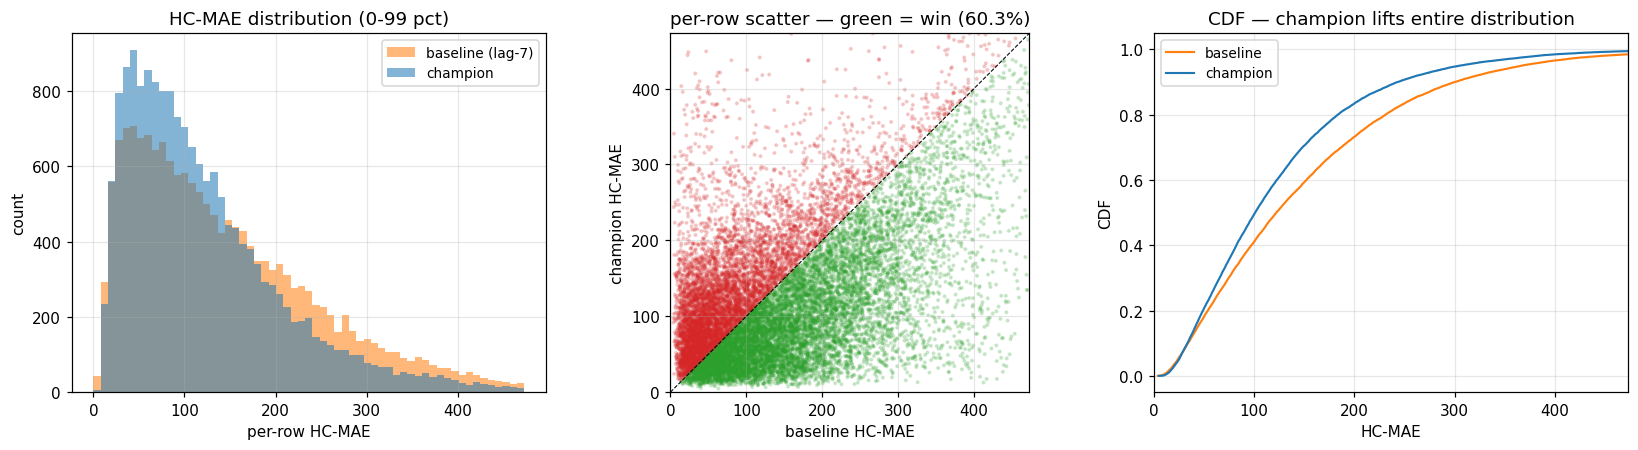


quantile summary:
      baseline  champion
0.05     23.64     24.90
0.25     63.83     57.16
0.50    121.92    100.93
0.75    206.95    164.46
0.95    366.43    304.31


In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
bins = np.linspace(0, np.quantile(np.r_[m['hc_mae'], m['baseline_hc_mae']], 0.99), 60)
axes[0].hist(m['baseline_hc_mae'], bins=bins, alpha=0.55, label='baseline (lag-7)', color='C1')
axes[0].hist(m['hc_mae'], bins=bins, alpha=0.55, label='champion', color='C0')
axes[0].set_xlabel('per-row HC-MAE'); axes[0].set_ylabel('count'); axes[0].legend(fontsize=9)
axes[0].set_title('HC-MAE distribution (0-99 pct)')

axes[1].scatter(m['baseline_hc_mae'], m['hc_mae'], s=3, alpha=0.18,
                c=np.where(m['win'], 'C2', 'C3'))
lim = float(np.quantile(np.r_[m['hc_mae'], m['baseline_hc_mae']], 0.99))
axes[1].plot([0, lim], [0, lim], 'k--', lw=0.7)
axes[1].set_xlim(0, lim); axes[1].set_ylim(0, lim); axes[1].set_aspect('equal')
axes[1].set_xlabel('baseline HC-MAE'); axes[1].set_ylabel('champion HC-MAE')
axes[1].set_title(f'per-row scatter — green = win ({m["win"].mean():.1%})')

xb = np.sort(m['baseline_hc_mae']); xm = np.sort(m['hc_mae'])
y = np.arange(1, len(xb) + 1) / len(xb)
axes[2].plot(xb, y, color='C1', lw=1.4, label='baseline')
axes[2].plot(xm, y, color='C0', lw=1.4, label='champion')
axes[2].set_xlabel('HC-MAE'); axes[2].set_ylabel('CDF'); axes[2].set_xlim(0, lim)
axes[2].set_title('CDF — champion lifts entire distribution')
axes[2].legend(fontsize=9)
plt.tight_layout(); plt.show()

print()
print('quantile summary:')
q = pd.DataFrame({
    'baseline': m['baseline_hc_mae'].quantile([0.05, 0.25, 0.5, 0.75, 0.95]),
    'champion': m['hc_mae'].quantile([0.05, 0.25, 0.5, 0.75, 0.95]),
})
print(q.round(2).to_string())

## 3. Per-row Δ distribution and cumulative gain

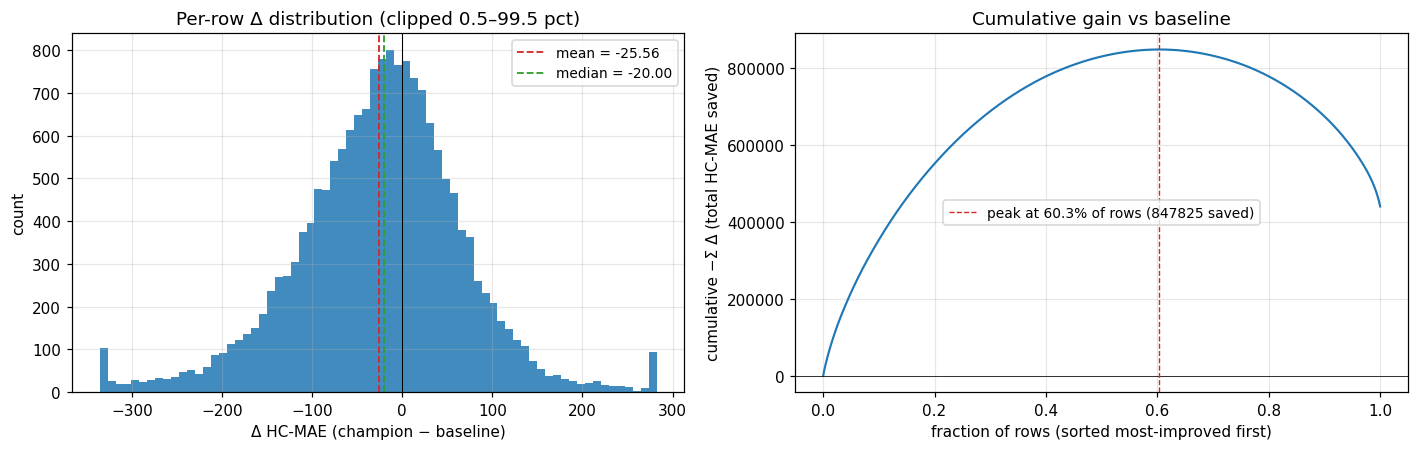


Δ quantiles  p05=-184.05  p25=-78.58  median=-20.00  p75=+30.45  p95=+115.45


In [4]:
d = m['delta_hc'].to_numpy()
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))

lo, hi = np.quantile(d, [0.005, 0.995])
axes[0].hist(d.clip(lo, hi), bins=70, color='C0', alpha=0.85)
axes[0].axvline(0, color='k', lw=0.7)
axes[0].axvline(d.mean(), color='C3', ls='--', lw=1.2, label=f'mean = {d.mean():+.2f}')
axes[0].axvline(np.median(d), color='C2', ls='--', lw=1.2, label=f'median = {np.median(d):+.2f}')
axes[0].set_xlabel('Δ HC-MAE (champion − baseline)')
axes[0].set_ylabel('count')
axes[0].set_title('Per-row Δ distribution (clipped 0.5–99.5 pct)')
axes[0].legend(fontsize=9)

order = np.argsort(d); cumgain = -np.cumsum(d[order])
frac = np.arange(1, len(d) + 1) / len(d)
axes[1].plot(frac, cumgain, lw=1.4, color='C0')
axes[1].axhline(0, color='k', lw=0.5)
imax = int(np.argmax(cumgain))
axes[1].axvline(frac[imax], color='C3', ls='--', lw=0.9,
                label=f'peak at {frac[imax]:.1%} of rows ({cumgain[imax]:.0f} saved)')
axes[1].set_xlabel('fraction of rows (sorted most-improved first)')
axes[1].set_ylabel('cumulative −Σ Δ (total HC-MAE saved)')
axes[1].set_title('Cumulative gain vs baseline')
axes[1].legend(fontsize=9)
plt.tight_layout(); plt.show()

print(f'\nΔ quantiles  p05={np.quantile(d, 0.05):+.2f}  p25={np.quantile(d, 0.25):+.2f}  '
      f'median={np.median(d):+.2f}  p75={np.quantile(d, 0.75):+.2f}  p95={np.quantile(d, 0.95):+.2f}')

## 4. Time series of HC-MAE and Δ over the test window

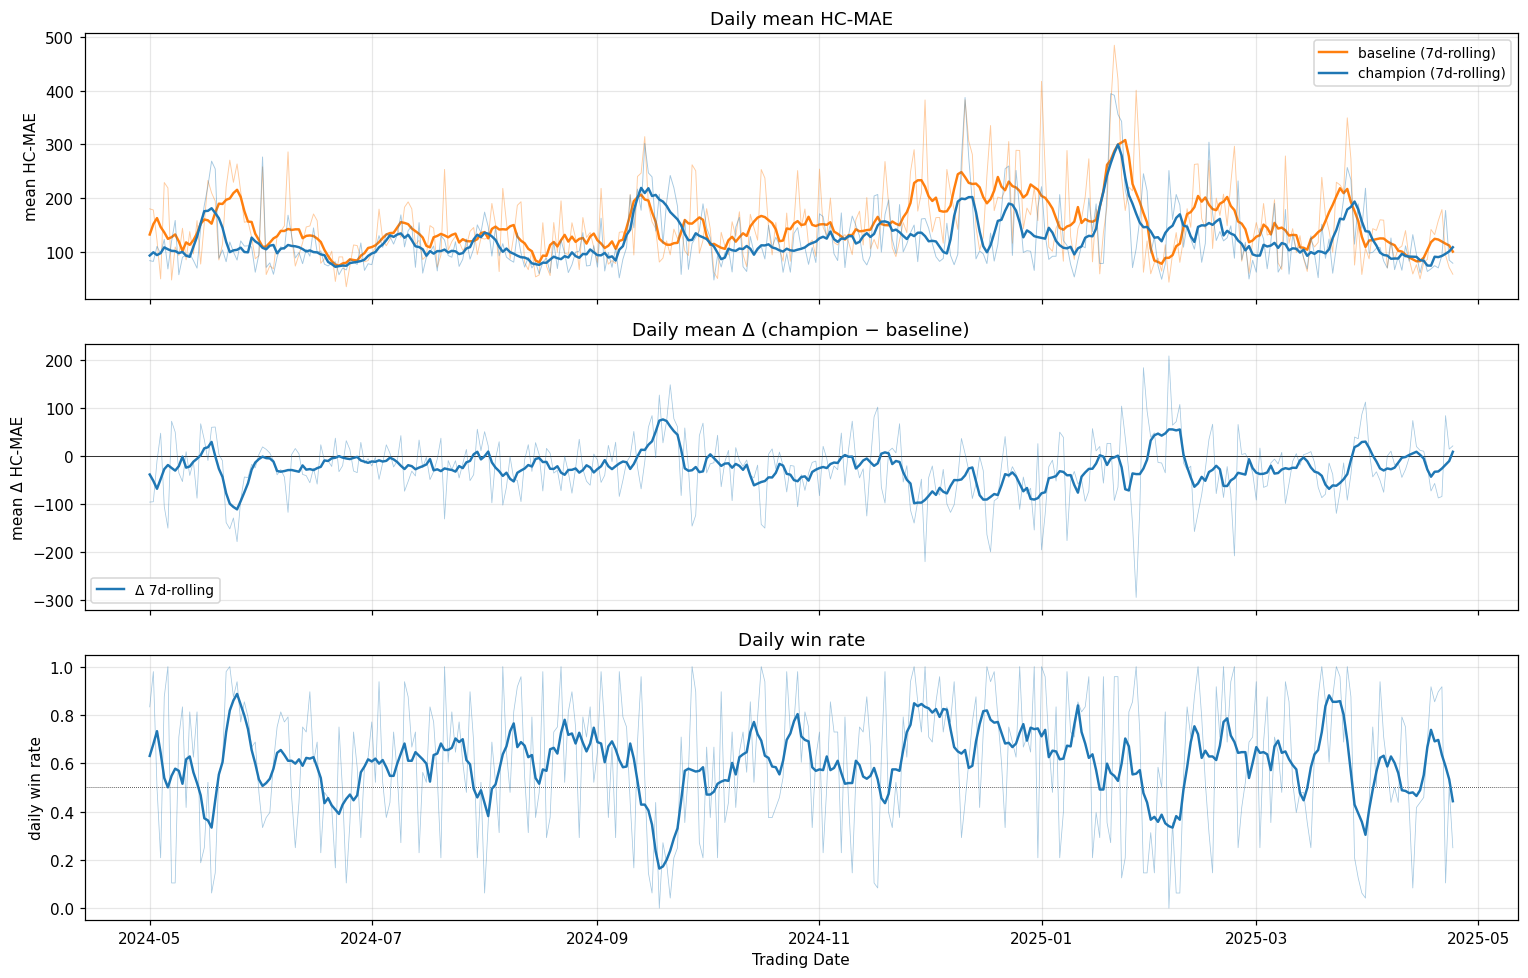

In [5]:
daily = m.groupby(m['Trading Date'].dt.date).agg(
    n=('hc_mae', 'size'),
    mean_hc=('hc_mae', 'mean'),
    mean_base_hc=('baseline_hc_mae', 'mean'),
    mean_delta=('delta_hc', 'mean'),
    win=('win', 'mean'),
).reset_index()
daily['Trading Date'] = pd.to_datetime(daily['Trading Date'])
daily['hc_7d'] = daily['mean_hc'].rolling(7, center=True, min_periods=3).mean()
daily['base_7d'] = daily['mean_base_hc'].rolling(7, center=True, min_periods=3).mean()
daily['delta_7d'] = daily['mean_delta'].rolling(7, center=True, min_periods=3).mean()
daily['win_7d'] = daily['win'].rolling(7, center=True, min_periods=3).mean()

fig, axes = plt.subplots(3, 1, figsize=(14, 9), sharex=True)
axes[0].plot(daily['Trading Date'], daily['mean_base_hc'], color='C1', lw=0.6, alpha=0.4)
axes[0].plot(daily['Trading Date'], daily['base_7d'],      color='C1', lw=1.6, label='baseline (7d-rolling)')
axes[0].plot(daily['Trading Date'], daily['mean_hc'],      color='C0', lw=0.6, alpha=0.4)
axes[0].plot(daily['Trading Date'], daily['hc_7d'],        color='C0', lw=1.6, label='champion (7d-rolling)')
axes[0].set_ylabel('mean HC-MAE')
axes[0].set_title('Daily mean HC-MAE')
axes[0].legend(loc='upper right', fontsize=9)

axes[1].axhline(0, color='k', lw=0.5)
axes[1].plot(daily['Trading Date'], daily['mean_delta'], color='C0', lw=0.5, alpha=0.4)
axes[1].plot(daily['Trading Date'], daily['delta_7d'],   color='C0', lw=1.6, label='Δ 7d-rolling')
axes[1].set_ylabel('mean Δ HC-MAE'); axes[1].set_title('Daily mean Δ (champion − baseline)')
axes[1].legend(loc='lower left', fontsize=9)

axes[2].axhline(0.5, color='k', lw=0.5, ls=':')
axes[2].plot(daily['Trading Date'], daily['win'],    color='C0', lw=0.5, alpha=0.4)
axes[2].plot(daily['Trading Date'], daily['win_7d'], color='C0', lw=1.6)
axes[2].set_ylabel('daily win rate'); axes[2].set_xlabel('Trading Date')
axes[2].set_title('Daily win rate')
plt.tight_layout(); plt.show()

## 5. Per-interval, per-weekday, and interval × weekday heatmap

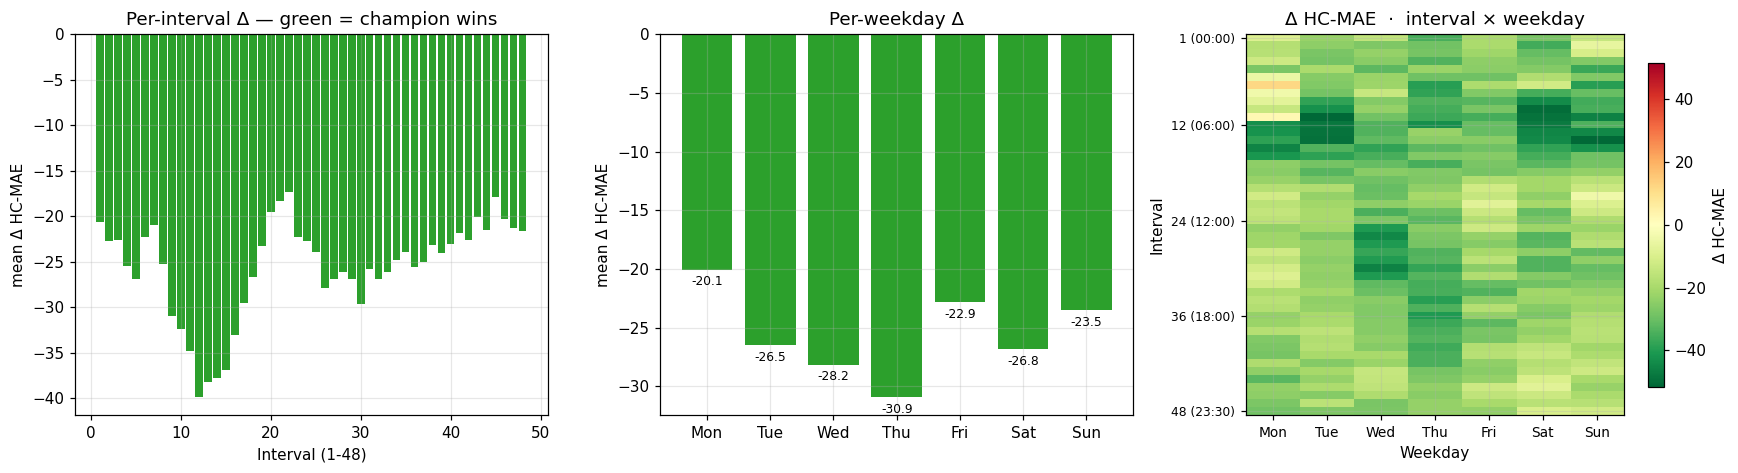


Weakest weekday: Mon (Δ=-20.05)
Strongest weekday: Thu (Δ=-30.92)


In [6]:
dow_labels = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
by_int = m.groupby('Interval Number').agg(delta=('delta_hc', 'mean'),
                                            win=('win', 'mean'),
                                            n=('hc_mae', 'size')).reset_index()
by_dow = m.groupby('dow').agg(delta=('delta_hc', 'mean'),
                              win=('win', 'mean')).reset_index()

fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
axes[0].bar(by_int['Interval Number'], by_int['delta'],
            color=np.where(by_int['delta'] < 0, 'C2', 'C3'))
axes[0].axhline(0, color='k', lw=0.5)
axes[0].set_xlabel('Interval (1-48)')
axes[0].set_ylabel('mean Δ HC-MAE')
axes[0].set_title('Per-interval Δ — green = champion wins')

axes[1].bar(np.arange(7), by_dow['delta'],
            color=np.where(by_dow['delta'] < 0, 'C2', 'C3'))
axes[1].axhline(0, color='k', lw=0.5)
axes[1].set_xticks(range(7)); axes[1].set_xticklabels(dow_labels)
axes[1].set_ylabel('mean Δ HC-MAE'); axes[1].set_title('Per-weekday Δ')
for i, v in enumerate(by_dow['delta']):
    axes[1].text(i, v + (0.5 if v >= 0 else -0.5), f'{v:+.1f}',
                 ha='center', va='bottom' if v >= 0 else 'top', fontsize=8)

pivot = (m.groupby(['Interval Number', 'dow'])['delta_hc']
         .mean().unstack('dow'))
vmax = float(np.nanmax(np.abs(pivot.values)))
im = axes[2].imshow(pivot.values, aspect='auto', cmap='RdYlGn_r',
                    vmin=-vmax, vmax=vmax)
axes[2].set_yticks([0, 11, 23, 35, 47])
axes[2].set_yticklabels(['1 (00:00)', '12 (06:00)', '24 (12:00)',
                         '36 (18:00)', '48 (23:30)'], fontsize=8)
axes[2].set_xticks(range(7)); axes[2].set_xticklabels(dow_labels, fontsize=9)
axes[2].set_ylabel('Interval'); axes[2].set_xlabel('Weekday')
axes[2].set_title('Δ HC-MAE  ·  interval × weekday')
fig.colorbar(im, ax=axes[2], shrink=0.85, label='Δ HC-MAE')
plt.tight_layout(); plt.show()

worst_dow = int(by_dow['delta'].idxmax()); best_dow = int(by_dow['delta'].idxmin())
print(f'\nWeakest weekday: {dow_labels[worst_dow]} (Δ={by_dow["delta"].iloc[worst_dow]:+.2f})')
print(f'Strongest weekday: {dow_labels[best_dow]} (Δ={by_dow["delta"].iloc[best_dow]:+.2f})')

## 6. Per-month detail — mean, median, IQR, win-rate

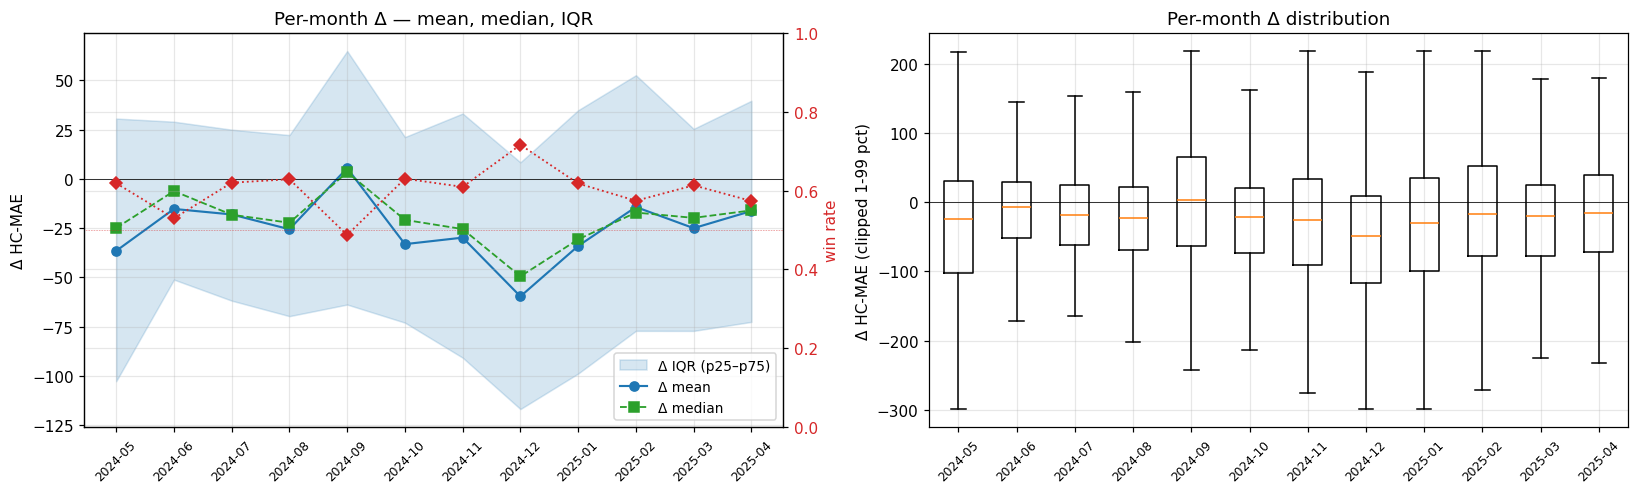


Per-month summary:
  month    n  delta_mean  delta_median  delta_p25  delta_p75  win_rate  hc_mean  base_mean
2024-05 1488      -36.56        -24.93    -102.75      30.62      0.62   116.10     152.66
2024-06 1440      -15.26         -6.21     -51.13      29.03      0.53    96.93     112.19
2024-07 1488      -18.06        -18.19     -61.82      24.98      0.62   111.71     129.77
2024-08 1488      -25.58        -22.28     -69.70      22.24      0.63    96.80     122.39
2024-09 1440        5.46          3.38     -63.80      64.89      0.49   150.39     144.93
2024-10 1488      -33.13        -20.82     -72.99      21.23      0.63   103.37     136.51
2024-11 1440      -29.83        -25.48     -90.78      33.19      0.61   135.30     165.13
2024-12 1488      -59.67        -49.49    -116.87       8.42      0.72   146.14     205.81
2025-01 1488      -34.07        -30.72     -98.84      34.86      0.62   166.87     200.93
2025-02 1344      -14.28        -17.11     -77.15      52.63      0.57

In [7]:
monthly = m.groupby('month').agg(
    n=('delta_hc', 'size'),
    delta_mean=('delta_hc', 'mean'),
    delta_median=('delta_hc', 'median'),
    delta_p25=('delta_hc', lambda x: x.quantile(0.25)),
    delta_p75=('delta_hc', lambda x: x.quantile(0.75)),
    win_rate=('win', 'mean'),
    hc_mean=('hc_mae', 'mean'),
    base_mean=('baseline_hc_mae', 'mean'),
).reset_index()

fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
x = np.arange(len(monthly))
ax = axes[0]
ax.fill_between(x, monthly['delta_p25'], monthly['delta_p75'],
                color='C0', alpha=0.18, label='Δ IQR (p25–p75)')
ax.plot(x, monthly['delta_mean'], 'o-', color='C0', lw=1.4, label='Δ mean')
ax.plot(x, monthly['delta_median'], 's--', color='C2', lw=1.2, label='Δ median')
ax.axhline(0, color='k', lw=0.5)
ax.set_xticks(x); ax.set_xticklabels(monthly['month'], rotation=45, fontsize=8)
ax.set_ylabel('Δ HC-MAE'); ax.set_title('Per-month Δ — mean, median, IQR')
ax.legend(loc='lower right', fontsize=9)

ax2 = ax.twinx()
ax2.plot(x, monthly['win_rate'], 'D:', color='C3', lw=1.2, label='win rate')
ax2.axhline(0.5, color='C3', lw=0.4, ls=':')
ax2.set_ylabel('win rate', color='C3'); ax2.set_ylim(0, 1.0)
ax2.tick_params(axis='y', labelcolor='C3')

lo, hi = np.quantile(m['delta_hc'], [0.01, 0.99])
data_by_month = [m[m['month'] == mo]['delta_hc'].clip(lower=lo, upper=hi)
                 for mo in monthly['month']]
axes[1].boxplot(data_by_month, showfliers=False)
axes[1].axhline(0, color='k', lw=0.5)
axes[1].set_xticks(np.arange(1, len(monthly) + 1))
axes[1].set_xticklabels(monthly['month'], rotation=45, fontsize=8)
axes[1].set_ylabel('Δ HC-MAE (clipped 1-99 pct)')
axes[1].set_title('Per-month Δ distribution')
plt.tight_layout(); plt.show()

print('\nPer-month summary:')
print(monthly.round(2).to_string(index=False))

## 7. Covariate correlation — what drives the per-row HC-MAE?

For each row, we compute Spearman ρ of `champion HC-MAE` and `Δ HC-MAE` against:
- `baseline_hc_mae` (how hard the row was for lag-7 → "difficulty")
- `dow` (day of week)
- `Interval Number`
- `true_total_mw` (total demand in MW)
- `vmax_mismatch` (pred_total − true_total, the volume mismatch the retrieval introduces)
- `retrieval_dist` (Ridge query L2 distance to the picked candidate, if present)
- `retrieved_age_days` (how old the picked historical curve is)
- `month_index`

         covariate  rho_vs_HC  p_vs_HC  rho_vs_delta  p_vs_delta
   baseline_hc_mae     0.4447   0.0000       -0.6547      0.0000
               dow     0.0080   0.2939        0.0005      0.9494
   Interval Number    -0.1298   0.0000        0.0090      0.2356
     true_total_mw    -0.0485   0.0000        0.0787      0.0000
     vmax_mismatch    -0.1436   0.0000       -0.1117      0.0000
    retrieval_dist    -0.0507   0.0000       -0.0627      0.0000
  retrieval_dist_2    -0.0417   0.0000       -0.0665      0.0000
retrieved_age_days     0.0170   0.0257        0.0428      0.0000
       bucket_size     0.0710   0.0000       -0.0204      0.0075
       month_index     0.0718   0.0000       -0.0208      0.0063


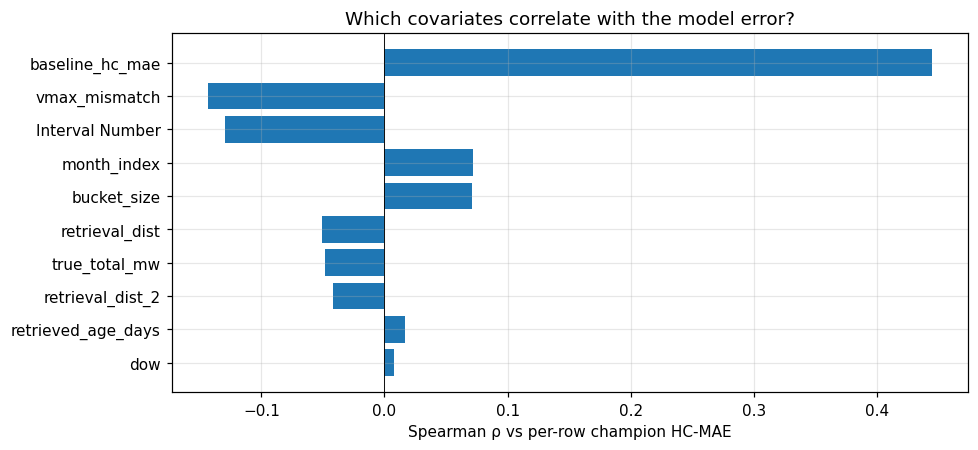

In [8]:
cov_rows = []
covariates = [
    ('baseline_hc_mae',  m['baseline_hc_mae']),
    ('dow',              m['dow']),
    ('Interval Number',  m['Interval Number']),
    ('true_total_mw',    m['true_total_mw']),
    ('vmax_mismatch',    m['vmax_mismatch']),
]
for opt in ('retrieval_dist', 'retrieval_dist_2', 'retrieved_age_days', 'bucket_size'):
    if opt in m.columns:
        covariates.append((opt, m[opt]))
covariates.append(('month_index', m['Trading Date'].dt.month + (m['Trading Date'].dt.year - 2024) * 12))

for name, x in covariates:
    mask = x.notna()
    rho_hc,    p_hc    = spearmanr(x[mask], m.loc[mask, 'hc_mae'])
    rho_delta, p_delta = spearmanr(x[mask], m.loc[mask, 'delta_hc'])
    cov_rows.append({
        'covariate': name,
        'rho_vs_HC':    rho_hc,
        'p_vs_HC':      p_hc,
        'rho_vs_delta': rho_delta,
        'p_vs_delta':   p_delta,
    })
cov_df = pd.DataFrame(cov_rows)
print(cov_df.round(4).to_string(index=False))

# bar plot of |ρ vs HC| ranked
order_idx = cov_df['rho_vs_HC'].abs().sort_values(ascending=True).index
fig, ax = plt.subplots(1, 1, figsize=(9, 4.2))
ax.barh(cov_df.loc[order_idx, 'covariate'], cov_df.loc[order_idx, 'rho_vs_HC'], color='C0')
ax.axvline(0, color='k', lw=0.6)
ax.set_xlabel('Spearman ρ vs per-row champion HC-MAE')
ax.set_title('Which covariates correlate with the model error?')
plt.tight_layout(); plt.show()

## 8. Difficulty stratification — does the champion help on hard rows?

Bin rows by *baseline HC-MAE* deciles (q1 easiest → q10 hardest), then show per-bin: champion mean, Δ, and win rate.

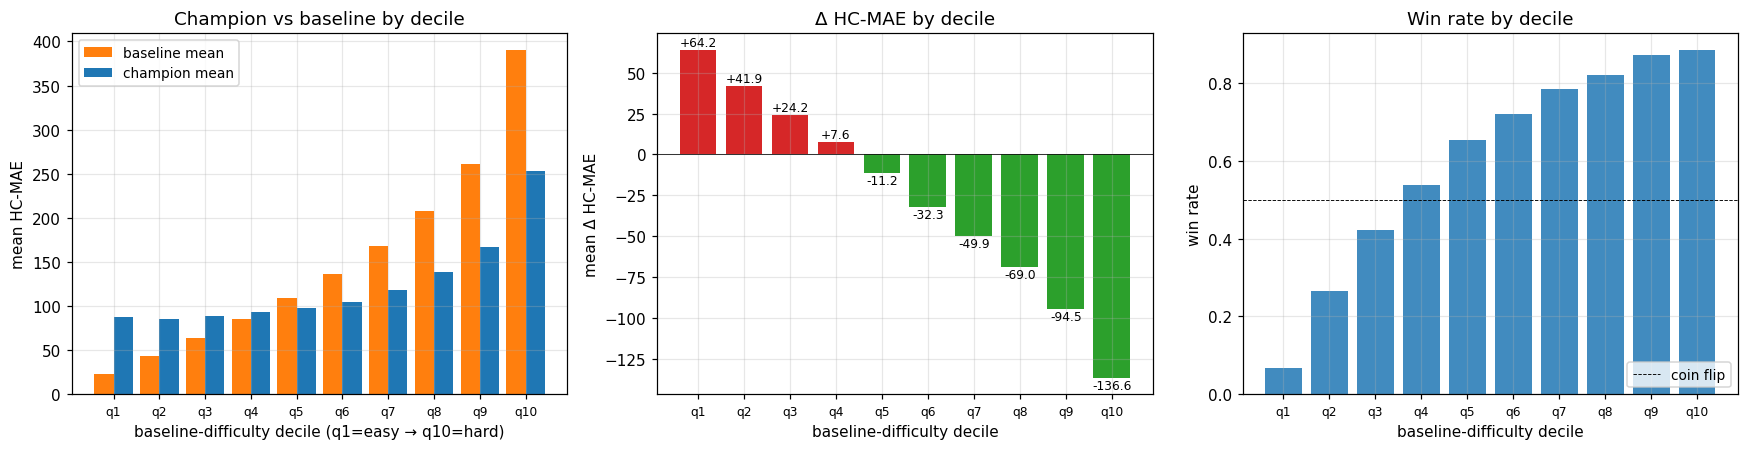


Per-difficulty decile:
 baseline_q  baseline_mean  model_mean    delta   win    n
          0         22.837      87.006   64.169 0.068 1724
          1         43.702      85.650   41.949 0.264 1723
          2         64.004      88.228   24.224 0.423 1723
          3         85.514      93.141    7.627 0.538 1723
          4        109.374      98.173  -11.201 0.653 1723
          5        136.678     104.329  -32.349 0.721 1723
          6        168.424     118.557  -49.867 0.785 1723
          7        207.708     138.714  -68.995 0.822 1723
          8        261.472     166.958  -94.514 0.873 1723
          9        389.907     253.292 -136.615 0.884 1724


In [9]:
n_bins = 10
m['baseline_q'] = pd.qcut(m['baseline_hc_mae'], n_bins, labels=False, duplicates='drop')
by_q = m.groupby('baseline_q').agg(
    baseline_mean=('baseline_hc_mae', 'mean'),
    model_mean=('hc_mae', 'mean'),
    delta=('delta_hc', 'mean'),
    win=('win', 'mean'),
    n=('hc_mae', 'size'),
).reset_index()

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
x = np.arange(len(by_q)); w = 0.42
axes[0].bar(x - w/2, by_q['baseline_mean'], w, color='C1', label='baseline mean')
axes[0].bar(x + w/2, by_q['model_mean'],   w, color='C0', label='champion mean')
axes[0].set_xticks(x); axes[0].set_xticklabels([f'q{i+1}' for i in x], fontsize=8)
axes[0].set_xlabel('baseline-difficulty decile (q1=easy → q10=hard)')
axes[0].set_ylabel('mean HC-MAE')
axes[0].set_title('Champion vs baseline by decile')
axes[0].legend(fontsize=9)

axes[1].bar(x, by_q['delta'], color=np.where(by_q['delta'] < 0, 'C2', 'C3'))
axes[1].axhline(0, color='k', lw=0.5)
axes[1].set_xticks(x); axes[1].set_xticklabels([f'q{i+1}' for i in x], fontsize=8)
axes[1].set_xlabel('baseline-difficulty decile')
axes[1].set_ylabel('mean Δ HC-MAE'); axes[1].set_title('Δ HC-MAE by decile')
for i, v in enumerate(by_q['delta']):
    axes[1].text(i, v + (0.5 if v >= 0 else -0.5), f'{v:+.1f}',
                 ha='center', va='bottom' if v >= 0 else 'top', fontsize=8)

axes[2].bar(x, by_q['win'], color='C0', alpha=0.85)
axes[2].axhline(0.5, color='k', lw=0.6, ls='--', label='coin flip')
axes[2].set_xticks(x); axes[2].set_xticklabels([f'q{i+1}' for i in x], fontsize=8)
axes[2].set_xlabel('baseline-difficulty decile')
axes[2].set_ylabel('win rate'); axes[2].set_title('Win rate by decile')
axes[2].legend(fontsize=9, loc='lower right')
plt.tight_layout(); plt.show()

print('\nPer-difficulty decile:')
print(by_q.round(3).to_string(index=False))

## 9. Per-volume residual / bias analysis

For each row evaluate (true − pred) price on a global volume grid. Mean signed residual = the model's bias profile (positive = champion under-predicts price at that volume). Mean absolute residual = the per-volume HC-MAE.

Computing per-volume residual matrices (may take ~10s)...
shape: (17232, 64)


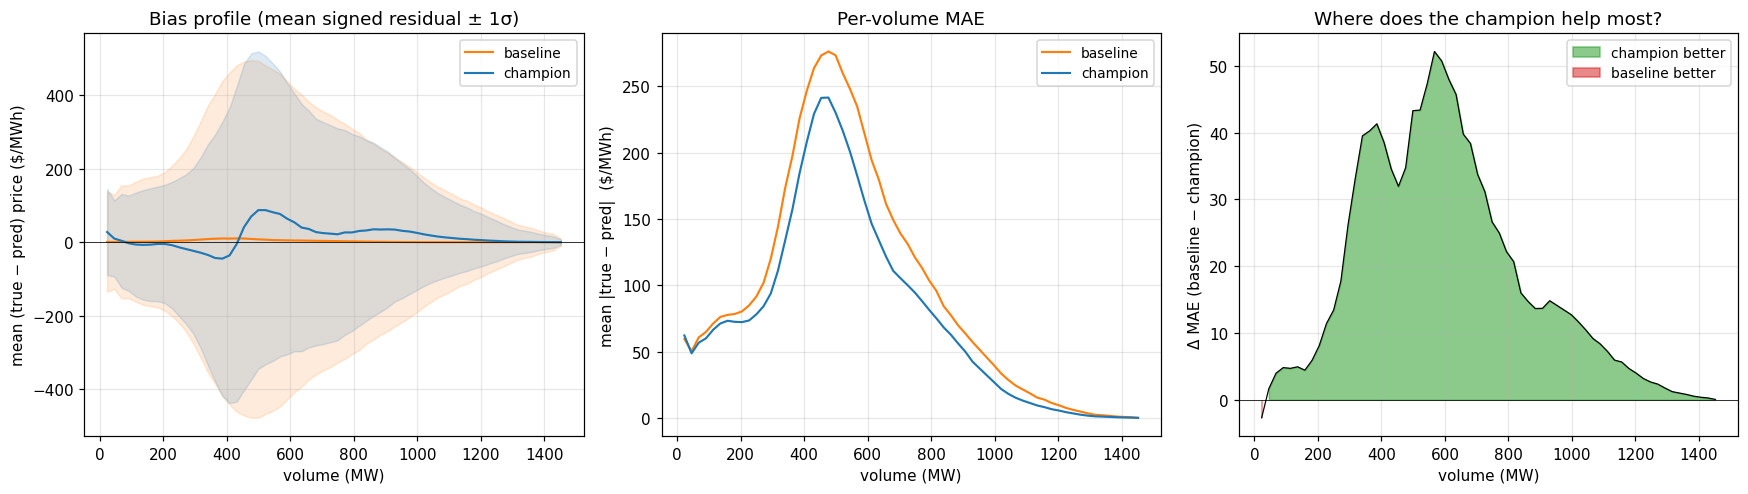


Largest improvement at volume 567 MW: Δ MAE = +52.14 $/MWh
Worst spot at         volume 23 MW: Δ MAE = -2.71 $/MWh


In [10]:
N_GRID = 64
V_MAX_GLOBAL = 1451.67
grid_global = np.linspace(V_MAX_GLOBAL / N_GRID, V_MAX_GLOBAL, N_GRID)


def per_volume_residual(qty_true, price_true, qty_pred, price_pred, grid):
    pt = _step_eval(np.asarray(qty_true, float), np.asarray(price_true, float), grid)
    pp = _step_eval(np.asarray(qty_pred, float), np.asarray(price_pred, float), grid)
    return pt - pp


def stack_residuals(qty_true_col, price_true_col, qty_pred_col, price_pred_col):
    out = np.empty((len(m), N_GRID), dtype=float)
    for i, (_, r) in enumerate(m.iterrows()):
        out[i] = per_volume_residual(r[qty_true_col], r[price_true_col],
                                     r[qty_pred_col], r[price_pred_col], grid_global)
    return out


print('Computing per-volume residual matrices (may take ~10s)...')
res_champ = stack_residuals('true_curve_qty', 'true_curve_price', 'pred_curve_qty', 'pred_curve_price')
res_base = stack_residuals('true_curve_qty', 'true_curve_price', 'base_curve_qty', 'base_curve_price')
print(f'shape: {res_champ.shape}')

mean_champ = np.nanmean(res_champ, axis=0)
mean_base = np.nanmean(res_base, axis=0)
std_champ = np.nanstd(res_champ, axis=0)
std_base = np.nanstd(res_base, axis=0)
mae_champ = np.nanmean(np.abs(res_champ), axis=0)
mae_base = np.nanmean(np.abs(res_base), axis=0)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
axes[0].fill_between(grid_global, mean_base - std_base, mean_base + std_base,
                     color='C1', alpha=0.15)
axes[0].plot(grid_global, mean_base, color='C1', lw=1.4, label='baseline')
axes[0].fill_between(grid_global, mean_champ - std_champ, mean_champ + std_champ,
                     color='C0', alpha=0.15)
axes[0].plot(grid_global, mean_champ, color='C0', lw=1.4, label='champion')
axes[0].axhline(0, color='k', lw=0.5)
axes[0].set_xlabel('volume (MW)')
axes[0].set_ylabel('mean (true − pred) price ($/MWh)')
axes[0].set_title('Bias profile (mean signed residual ± 1σ)')
axes[0].legend(fontsize=9)

axes[1].plot(grid_global, mae_base, color='C1', lw=1.4, label='baseline')
axes[1].plot(grid_global, mae_champ, color='C0', lw=1.4, label='champion')
axes[1].set_xlabel('volume (MW)')
axes[1].set_ylabel('mean |true − pred|  ($/MWh)')
axes[1].set_title('Per-volume MAE')
axes[1].legend(fontsize=9)

improvement = mae_base - mae_champ
axes[2].fill_between(grid_global, 0, improvement,
                     where=(improvement >= 0), color='C2', alpha=0.55, label='champion better')
axes[2].fill_between(grid_global, 0, improvement,
                     where=(improvement < 0), color='C3', alpha=0.55, label='baseline better')
axes[2].plot(grid_global, improvement, color='k', lw=0.8)
axes[2].axhline(0, color='k', lw=0.5)
axes[2].set_xlabel('volume (MW)')
axes[2].set_ylabel('Δ MAE (baseline − champion)')
axes[2].set_title('Where does the champion help most?')
axes[2].legend(fontsize=9)
plt.tight_layout(); plt.show()

best_vol = grid_global[int(np.argmax(improvement))]
worst_vol = grid_global[int(np.argmin(improvement))]
print(f'\nLargest improvement at volume {best_vol:.0f} MW: Δ MAE = {improvement.max():+.2f} $/MWh')
print(f'Worst spot at         volume {worst_vol:.0f} MW: Δ MAE = {improvement.min():+.2f} $/MWh')

## 10. Per-quantile residual — bias in 5 volume bands

Split the volume axis into 5 quantile bands `[0, 20, 40, 60, 80, 100] %` of `V_max_global`. Report mean signed residual and mean |residual| in each band.

   band  champ_mean_signed  champ_mean_abs  base_mean_signed  base_mean_abs  delta_mean_abs
  0–20%              -2.73           68.29              1.96          74.82           -6.53
 20–40%              17.47          187.03              8.09         225.98          -38.95
 40–60%              33.91          104.09              3.13         135.82          -31.74
 60–80%              21.89           26.33              0.26          37.18          -10.85
80–100%               2.37            2.37             -0.00           4.27           -1.90


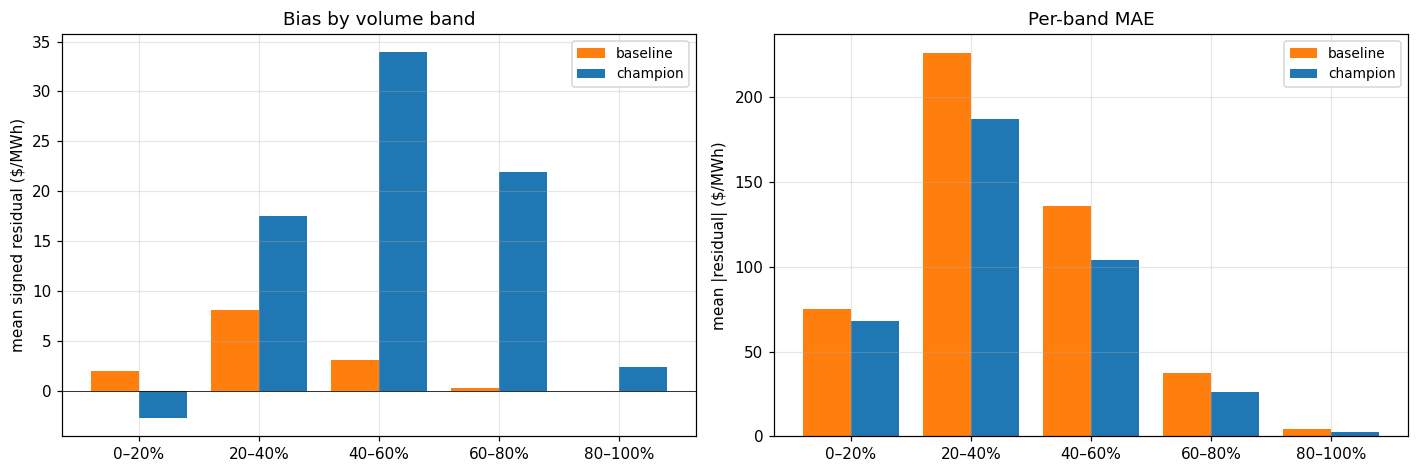

In [11]:
bands = [(0, 0.2), (0.2, 0.4), (0.4, 0.6), (0.6, 0.8), (0.8, 1.0)]
labels = [f'{int(a*100)}–{int(b*100)}%' for a, b in bands]
band_stats = []
for (a, b), lab in zip(bands, labels):
    sel = (grid_global >= a * V_MAX_GLOBAL) & (grid_global < b * V_MAX_GLOBAL)
    sub_champ = res_champ[:, sel].ravel()
    sub_base = res_base[:, sel].ravel()
    band_stats.append({
        'band': lab,
        'champ_mean_signed': float(np.nanmean(sub_champ)),
        'champ_mean_abs':    float(np.nanmean(np.abs(sub_champ))),
        'base_mean_signed':  float(np.nanmean(sub_base)),
        'base_mean_abs':     float(np.nanmean(np.abs(sub_base))),
        'delta_mean_abs':    float(np.nanmean(np.abs(sub_champ)) - np.nanmean(np.abs(sub_base))),
    })
band_df = pd.DataFrame(band_stats)
print(band_df.round(2).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
x = np.arange(len(band_df)); w = 0.4
axes[0].bar(x - w/2, band_df['base_mean_signed'], w, color='C1', label='baseline')
axes[0].bar(x + w/2, band_df['champ_mean_signed'], w, color='C0', label='champion')
axes[0].axhline(0, color='k', lw=0.5)
axes[0].set_xticks(x); axes[0].set_xticklabels(band_df['band'])
axes[0].set_ylabel('mean signed residual ($/MWh)')
axes[0].set_title('Bias by volume band')
axes[0].legend(fontsize=9)

axes[1].bar(x - w/2, band_df['base_mean_abs'], w, color='C1', label='baseline')
axes[1].bar(x + w/2, band_df['champ_mean_abs'], w, color='C0', label='champion')
axes[1].set_xticks(x); axes[1].set_xticklabels(band_df['band'])
axes[1].set_ylabel('mean |residual| ($/MWh)')
axes[1].set_title('Per-band MAE')
axes[1].legend(fontsize=9)
plt.tight_layout(); plt.show()

## 11. Retrieved-date analysis — how old are the picked candidates, do older retrievals do worse?

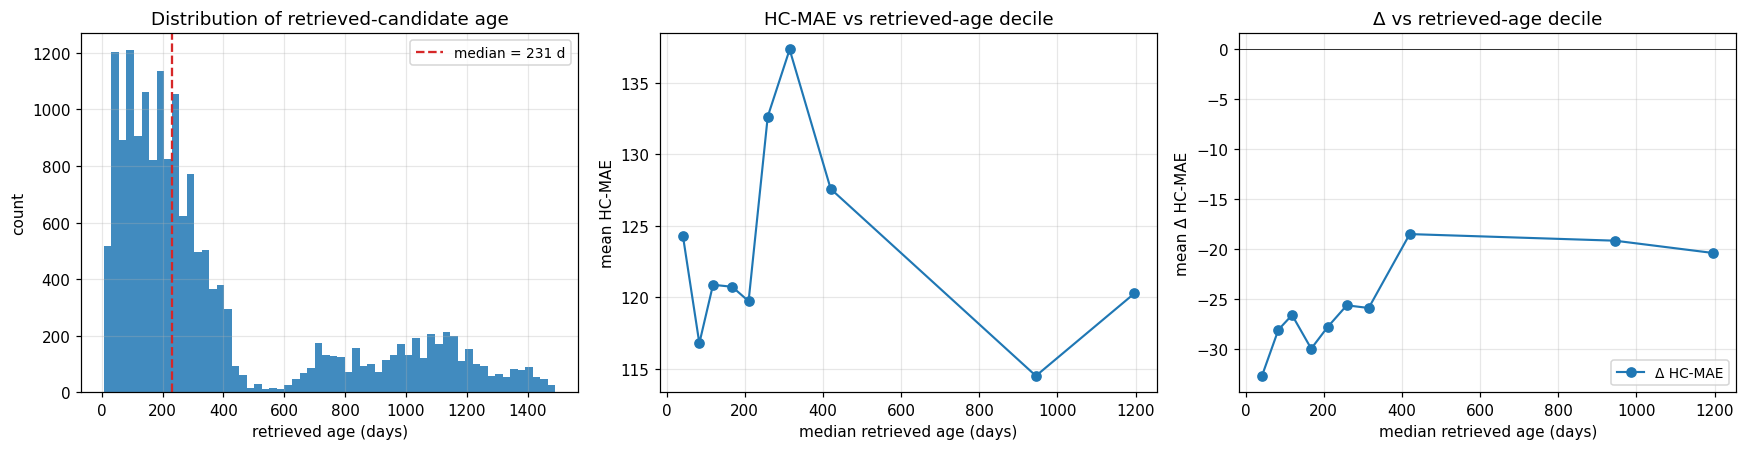

 age_q  median_age  hc_mean   delta   win
     0        42.0  124.290 -32.649 0.630
     1        84.0  116.792 -28.036 0.614
     2       119.0  120.876 -26.563 0.622
     3       168.0  120.735 -29.927 0.616
     4       210.0  119.731 -27.761 0.623
     5       259.0  132.625 -25.590 0.609
     6       315.0  137.308 -25.858 0.577
     7       420.0  127.573 -18.466 0.587
     8       945.0  114.514 -19.125 0.554
     9      1197.0  120.275 -20.361 0.593


In [12]:
if 'retrieved_age_days' in m.columns:
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))

    axes[0].hist(m['retrieved_age_days'].dropna(), bins=60, color='C0', alpha=0.85)
    axes[0].set_xlabel('retrieved age (days)')
    axes[0].set_ylabel('count')
    axes[0].axvline(m['retrieved_age_days'].median(), color='C3', ls='--',
                    label=f'median = {m["retrieved_age_days"].median():.0f} d')
    axes[0].set_title('Distribution of retrieved-candidate age')
    axes[0].legend(fontsize=9)

    # bin by age decile, plot mean HC-MAE
    m['age_q'] = pd.qcut(m['retrieved_age_days'], 10, labels=False, duplicates='drop')
    by_age = m.groupby('age_q').agg(
        median_age=('retrieved_age_days', 'median'),
        hc_mean=('hc_mae', 'mean'),
        delta=('delta_hc', 'mean'),
        win=('win', 'mean'),
    ).reset_index()
    axes[1].plot(by_age['median_age'], by_age['hc_mean'], 'o-', color='C0', lw=1.4)
    axes[1].set_xlabel('median retrieved age (days)')
    axes[1].set_ylabel('mean HC-MAE')
    axes[1].set_title('HC-MAE vs retrieved-age decile')

    axes[2].plot(by_age['median_age'], by_age['delta'], 'o-', color='C0', lw=1.4,
                 label='Δ HC-MAE')
    axes[2].axhline(0, color='k', lw=0.5)
    axes[2].set_xlabel('median retrieved age (days)')
    axes[2].set_ylabel('mean Δ HC-MAE')
    axes[2].set_title('Δ vs retrieved-age decile')
    axes[2].legend(fontsize=9)
    plt.tight_layout(); plt.show()

    print(by_age.round(3).to_string(index=False))
else:
    print('retrieved_date / retrieved_age_days not in predictions — skipping')

## 12. Example curves — one random sample per 5%-percentile of champion HC-MAE

Predictions are binned into 20 groups by the **champion's per-row HC-MAE** at 5%-step percentiles (p0–p5, p5–p10, …, p95–p100). One random sample is drawn from each bin and plotted in a 5×4 grid, ordered from easiest (top-left) to hardest (bottom-right) prediction.

- Black = actual demand curve
- Orange = lag-7 baseline (`base_curve_qty`/`base_curve_price`)
- Blue = champion prediction (`pred_curve_qty`/`pred_curve_price`)

Plot background:
- **very light green** when the champion beats the baseline on that row (Δ < 0)
- **very light red** when the baseline beats the champion (Δ ≥ 0)

Re-run cell to draw a fresh random sample within each bin.

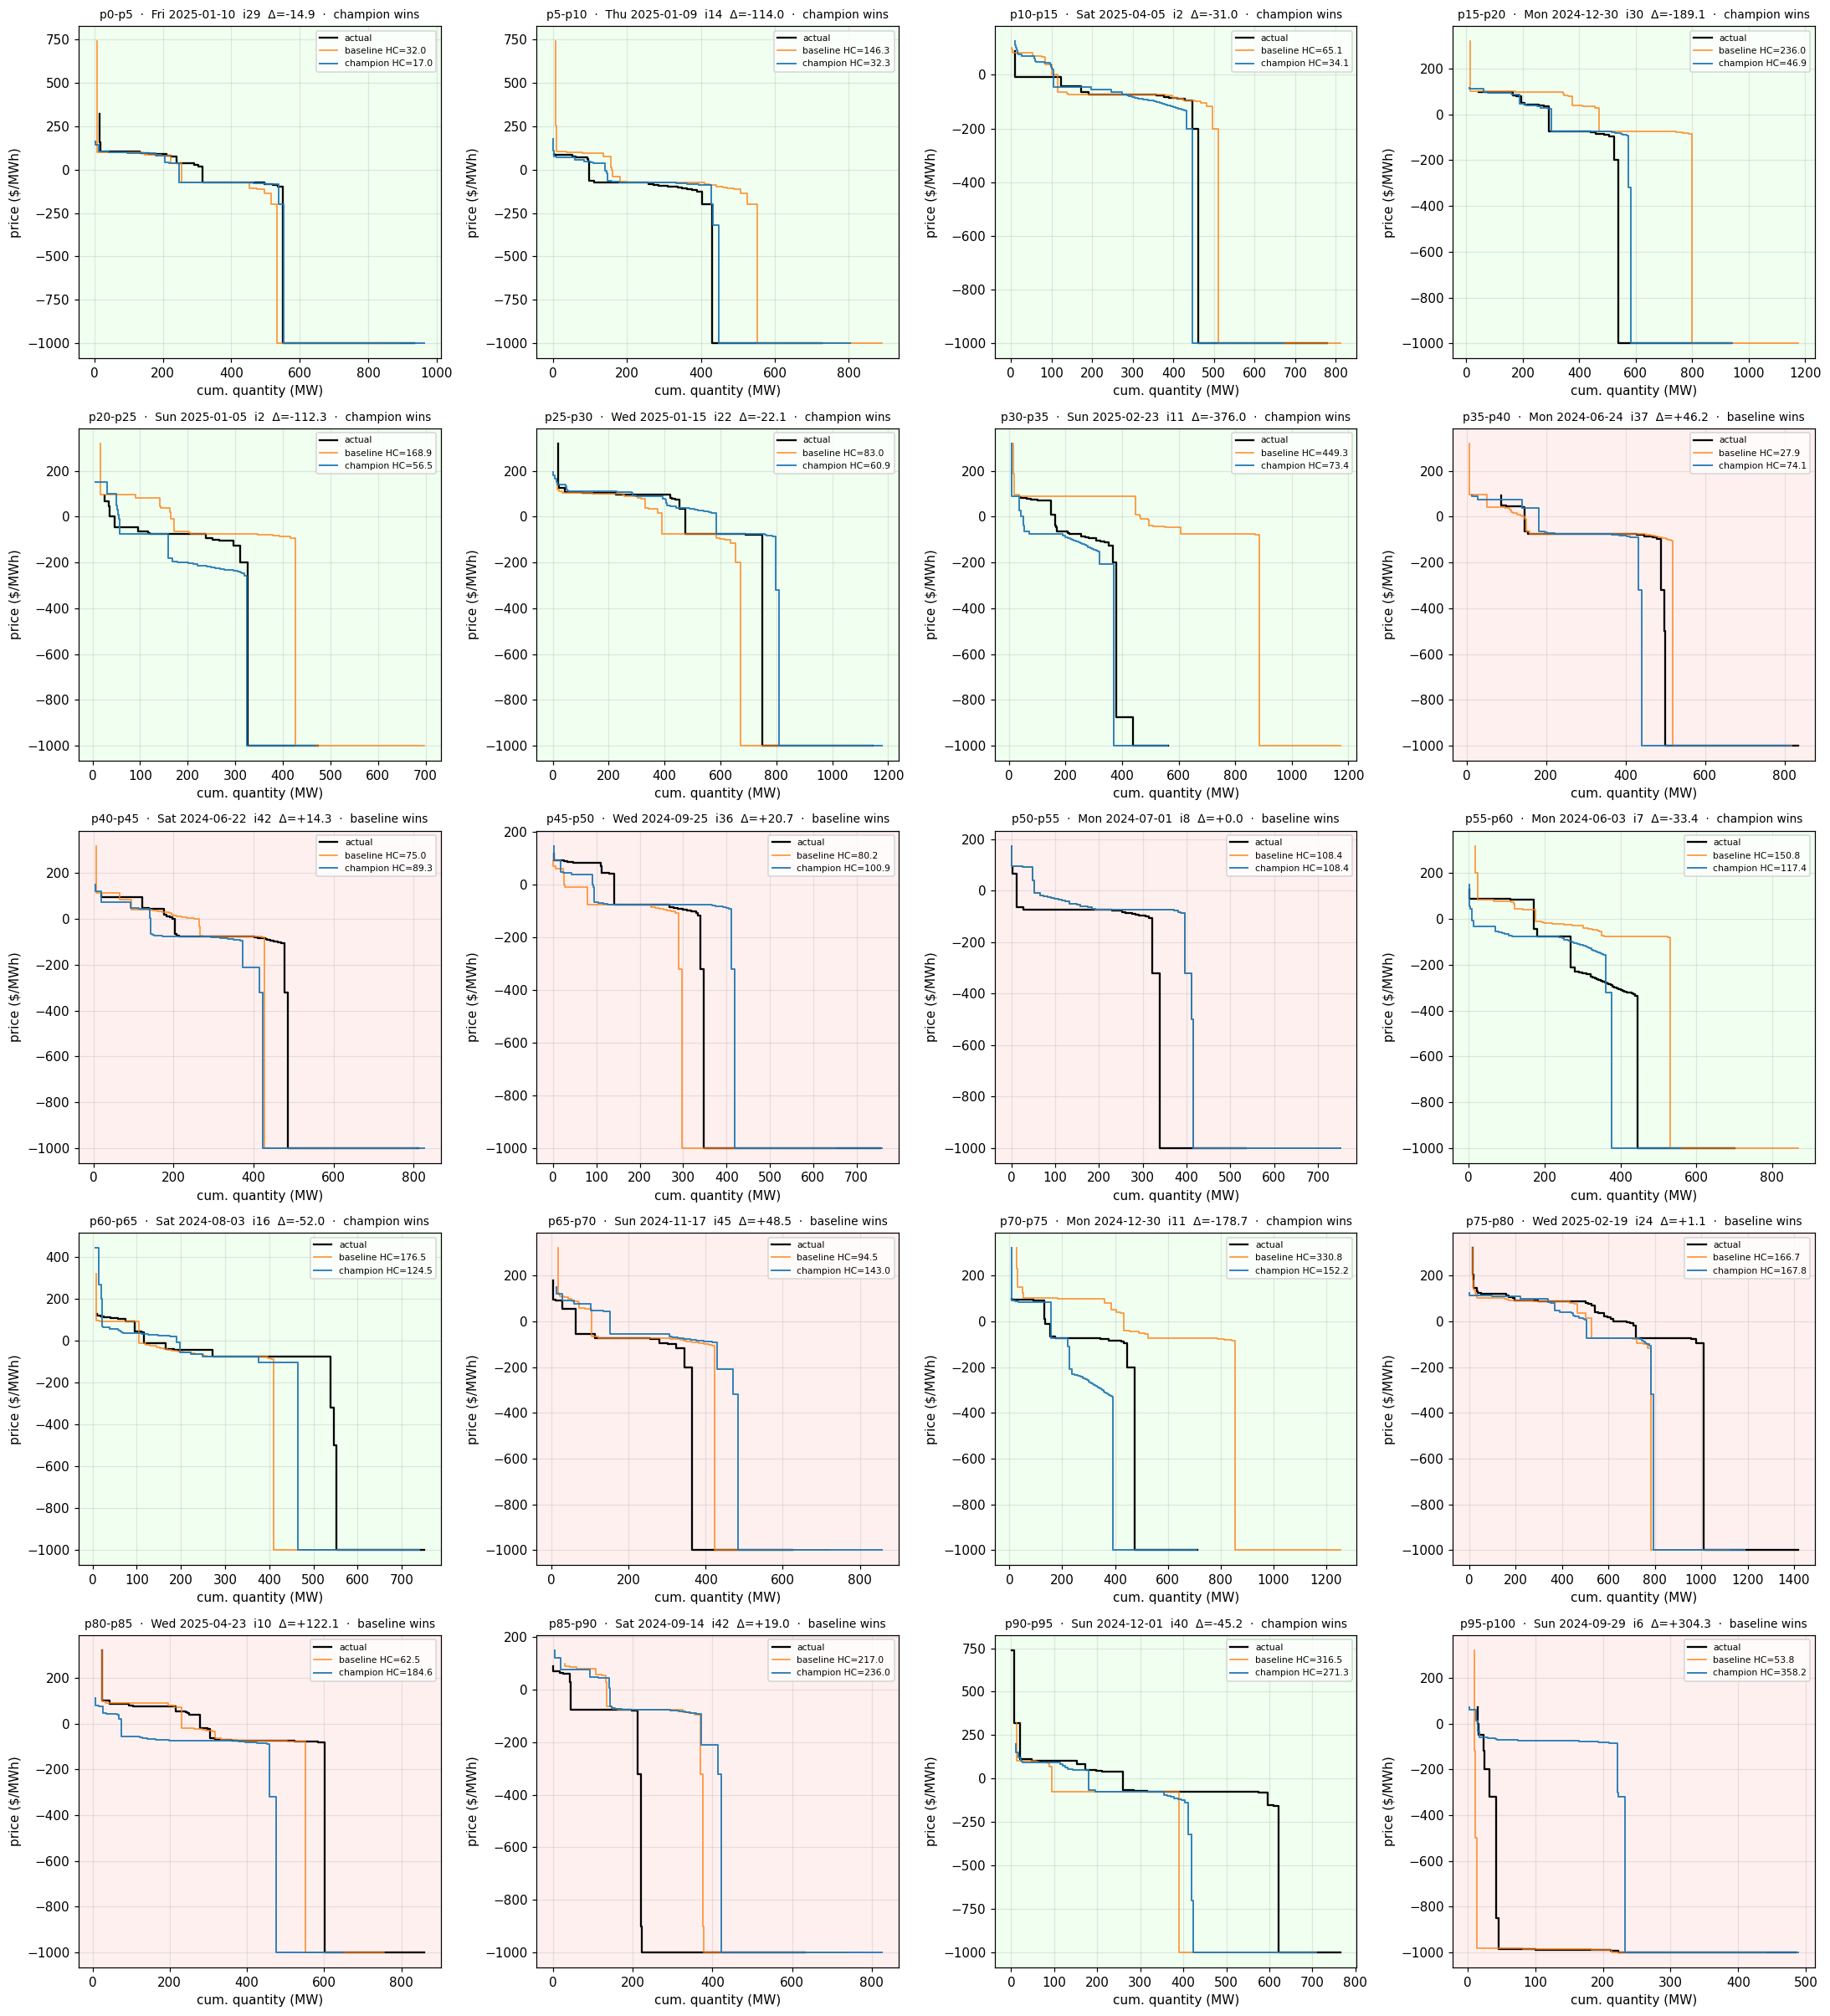

Per-percentile-bin summary:
            n  hc_mean  base_mean  delta_mean  win_rate
p0-p5     862    18.46      92.88      -74.42      0.96
p5-p10    862    29.00      98.94      -69.94      0.90
p10-p15   861    37.27     102.78      -65.51      0.82
p15-p20   862    44.94     101.11      -56.17      0.75
p20-p25   861    53.00     103.40      -50.40      0.73
p25-p30   862    61.21     113.01      -51.80      0.68
p30-p35   861    69.56     111.57      -42.01      0.63
p35-p40   862    78.07     113.18      -35.11      0.58
p40-p45   861    86.65     119.86      -33.21      0.59
p45-p50   862    96.05     123.92      -27.87      0.57
p50-p55   862   105.94     127.68      -21.74      0.52
p55-p60   861   116.73     136.60      -19.87      0.54
p60-p65   862   128.72     140.21      -11.49      0.48
p65-p70   861   141.14     151.85      -10.71      0.49
p70-p75   862   156.18     159.35       -3.17      0.49
p75-p80   861   173.70     172.53        1.17      0.48
p80-p85   862   195.

In [13]:
def plot_row(ax, r, title):
    ax.step(r['true_curve_qty'], r['true_curve_price'], where='pre',
            color='black', lw=1.5, label='actual')
    ax.step(r['base_curve_qty'], r['base_curve_price'], where='pre',
            color='C1', lw=1.1, alpha=0.85, label=f'baseline HC={r["baseline_hc_mae"]:.1f}')
    ax.step(r['pred_curve_qty'], r['pred_curve_price'], where='pre',
            color='C0', lw=1.3, alpha=0.9, label=f'champion HC={r["hc_mae"]:.1f}')
    ax.set_title(title, fontsize=9)
    ax.set_xlabel('cum. quantity (MW)'); ax.set_ylabel('price ($/MWh)')
    ax.legend(fontsize=7, loc='best')


N_BINS = 20
LIGHT_GREEN = '#f0fff0'  # honeydew — champion wins
LIGHT_RED   = '#fff0f0'  # lavender-blush — baseline wins

# Bin by per-row champion HC-MAE (ascending: bin 0 = easiest, bin 19 = hardest)
m['hc_bin'] = pd.qcut(m['hc_mae'], N_BINS, labels=False, duplicates='drop')
rng = np.random.default_rng()

fig, axes = plt.subplots(5, 4, figsize=(20, 22))
for bin_id, ax in enumerate(axes.flat):
    sub = m[m['hc_bin'] == bin_id]
    if len(sub) == 0:
        ax.set_visible(False)
        continue
    r = sub.sample(1, random_state=rng.integers(1_000_000)).iloc[0]
    bg = LIGHT_GREEN if r['delta_hc'] < 0 else LIGHT_RED
    ax.set_facecolor(bg)
    date_str = pd.Timestamp(r['Trading Date']).strftime('%a %Y-%m-%d')
    p_lo, p_hi = bin_id * 5, (bin_id + 1) * 5
    verdict = 'champion wins' if r['delta_hc'] < 0 else 'baseline wins'
    title = (f'p{p_lo}-p{p_hi}  ·  {date_str}  i{int(r["Interval Number"])}  '
             f'Δ={r["delta_hc"]:+.1f}  ·  {verdict}')
    plot_row(ax, r, title)
plt.tight_layout(); plt.show()

# Per-bin win-rate summary alongside the visual
by_bin = m.groupby('hc_bin').agg(
    n=('hc_mae', 'size'),
    hc_mean=('hc_mae', 'mean'),
    base_mean=('baseline_hc_mae', 'mean'),
    delta_mean=('delta_hc', 'mean'),
    win_rate=('win', 'mean'),
).round(2)
by_bin.index = [f'p{i*5}-p{(i+1)*5}' for i in by_bin.index]
print('Per-percentile-bin summary:')
print(by_bin.to_string())

## 13. Example curves — 5×5 grid by (Δ HC-MAE quintile × champion HC-MAE quintile)

Two-dimensional binning of the same per-row examples:

- **Rows** = quintiles of **signed Δ HC-MAE** (`champion − baseline`), ascending. Row 0 = lowest Δ (champion wins by the largest margin), Row 4 = highest Δ (baseline wins by the largest margin).
- **Columns** = quintiles of **champion HC-MAE**, ascending. Col 0 = easiest predictions, Col 4 = hardest.

One random sample per (row, col) cell. Same background convention as §12 — very light green when champion wins on the row, very light red when baseline wins.

This lets you eyeball *what kind of curve* shows up in each error regime: e.g. top-row × right-column = champion saves the most HC-MAE on the hardest auctions, top-row × left-column = champion saves a lot even on easy auctions.

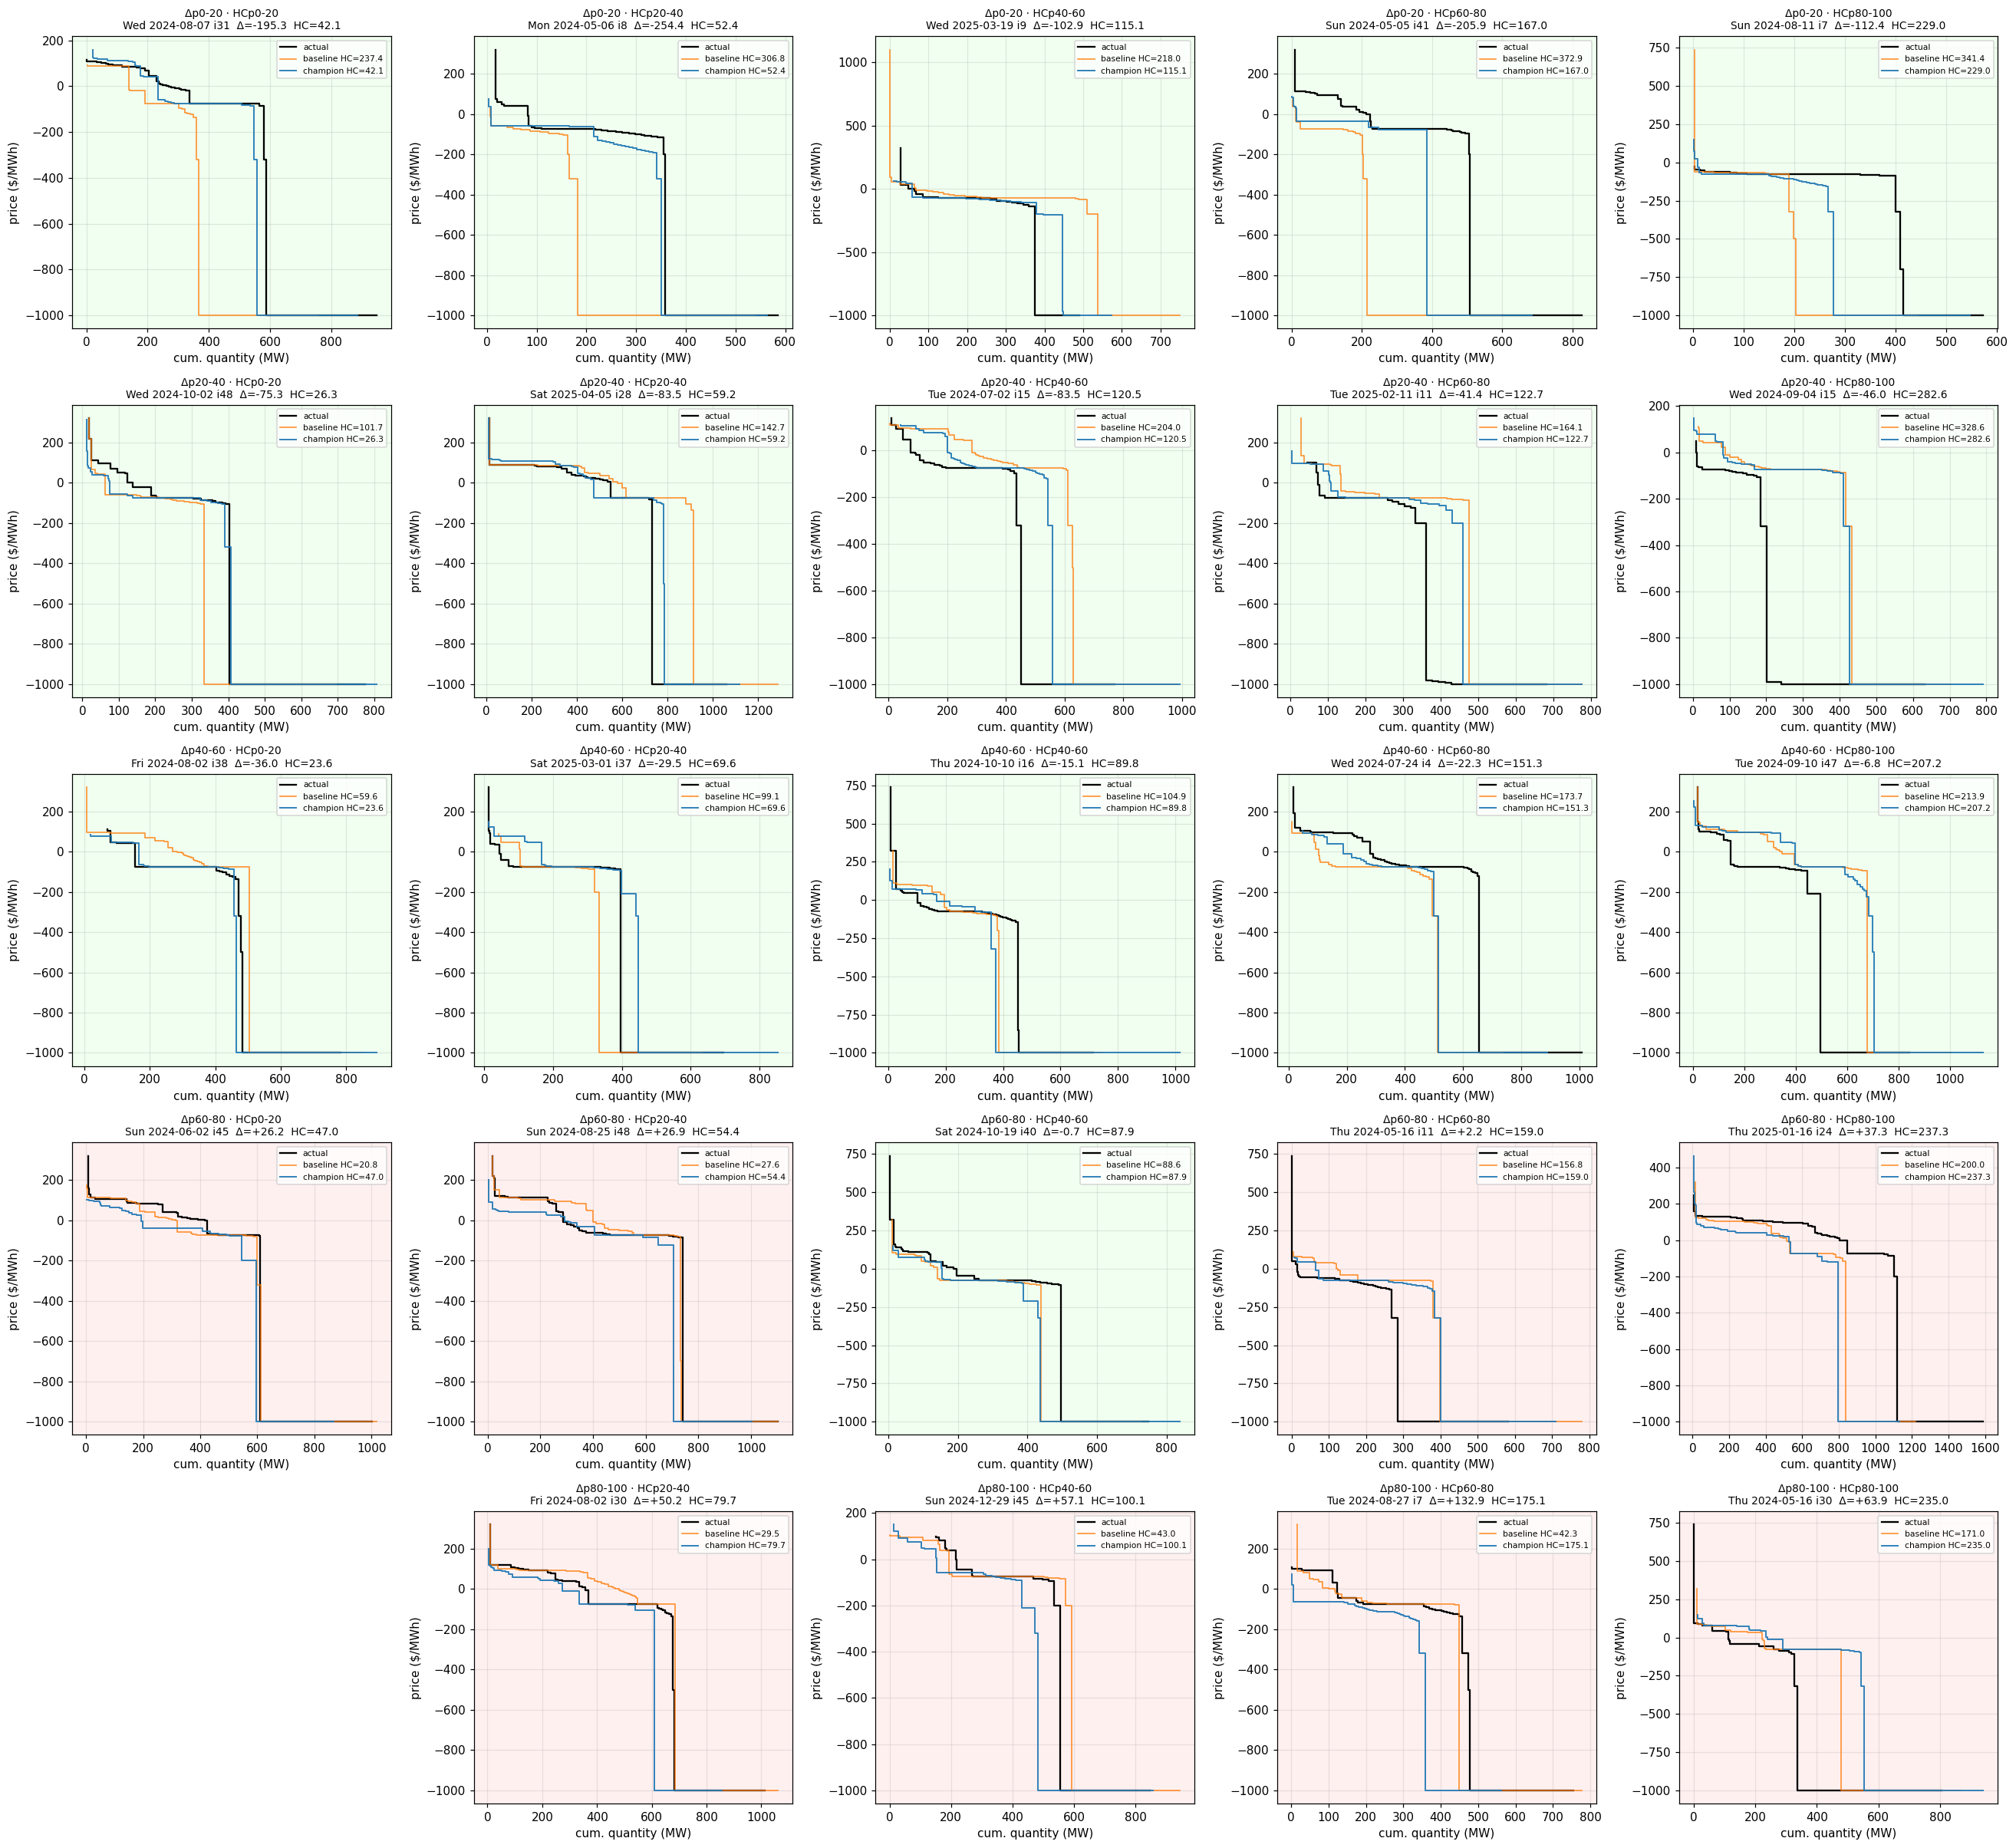

Cell counts (rows = Δ-quintile, cols = champion-HC-quintile):
hc_q         0      1      2       3       4
delta_q                                     
0        949.0  743.0  678.0   574.0   503.0
1        990.0  715.0  601.0   562.0   578.0
2        998.0  788.0  618.0   528.0   514.0
3        510.0  981.0  760.0   609.0   586.0
4          NaN  219.0  789.0  1173.0  1266.0

Mean Δ per cell:
hc_q          0       1       2       3       4
delta_q                                        
0       -158.49 -168.12 -156.58 -158.73 -156.91
1        -65.34  -65.66  -66.06  -65.84  -66.02
2        -20.67  -19.81  -19.56  -20.91  -20.25
3         12.69   21.83   22.00   21.67   20.24
4           NaN   52.85   66.88   89.61  132.92

Mean champion HC-MAE per cell:
hc_q         0      1       2       3       4
delta_q                                      
0        31.52  65.02  101.46  148.68  265.15
1        31.08  64.29  100.10  150.79  269.69
2        31.68  64.64  100.90  150.63  265.19
3      

In [14]:
N_BINS_2D = 5
LIGHT_GREEN_2D = '#f0fff0'
LIGHT_RED_2D = '#fff0f0'

m['delta_q'] = pd.qcut(m['delta_hc'], N_BINS_2D, labels=False, duplicates='drop')
m['hc_q']    = pd.qcut(m['hc_mae'],   N_BINS_2D, labels=False, duplicates='drop')

rng2 = np.random.default_rng()
fig, axes = plt.subplots(N_BINS_2D, N_BINS_2D, figsize=(24, 22))
for row in range(N_BINS_2D):
    for col in range(N_BINS_2D):
        ax = axes[row, col]
        cell = m[(m['delta_q'] == row) & (m['hc_q'] == col)]
        if len(cell) == 0:
            ax.set_visible(False)
            continue
        r = cell.sample(1, random_state=rng2.integers(1_000_000)).iloc[0]
        bg = LIGHT_GREEN_2D if r['delta_hc'] < 0 else LIGHT_RED_2D
        ax.set_facecolor(bg)
        date_str = pd.Timestamp(r['Trading Date']).strftime('%a %Y-%m-%d')
        dlo, dhi = row * 20, (row + 1) * 20
        hlo, hhi = col * 20, (col + 1) * 20
        title = (f'Δp{dlo}-{dhi} · HCp{hlo}-{hhi}\n'
                 f'{date_str} i{int(r["Interval Number"])}  '
                 f'Δ={r["delta_hc"]:+.1f}  HC={r["hc_mae"]:.1f}')
        plot_row(ax, r, title)
plt.tight_layout(); plt.show()

# Per-cell summary table (counts and mean Δ)
cell_n     = m.groupby(['delta_q', 'hc_q']).size().unstack('hc_q')
cell_delta = m.groupby(['delta_q', 'hc_q'])['delta_hc'].mean().unstack('hc_q')
cell_hc    = m.groupby(['delta_q', 'hc_q'])['hc_mae'].mean().unstack('hc_q')
print('Cell counts (rows = Δ-quintile, cols = champion-HC-quintile):')
print(cell_n.to_string())
print('\nMean Δ per cell:')
print(cell_delta.round(2).to_string())
print('\nMean champion HC-MAE per cell:')
print(cell_hc.round(2).to_string())

## 14. Example curves with residual diagnostics — 5×5 grid

Same 5×5 binning as §13 (rows = Δ-quintile, cols = champion-HC-MAE-quintile), but each panel now has **two stacked plots**:

- **Top (curves):** the three step curves, as in §13.
- **Bottom (residual strips):** `|true(V) − pred(V)|` plotted **on each pair's own V-grid**. The mean of each shaded area is *exactly* the reported HC-MAE for that pair, because `curve_hc_mae_distance` integrates over each pair's union support (`min/max of true & pred quantities`), not the union of all three curves.

Dotted vertical lines at the right edge of each strip mark each pair's `v_max`. For the Ridge retrieval (this notebook), both predictions are *real curves* with realistic `qty` arrays, so the per-pair `v_max` values are usually similar — there's no V-range-bias artifact like the synthetic-blend notebook has. The residual strips simply reveal where on the volume axis each method's price prediction goes wrong.

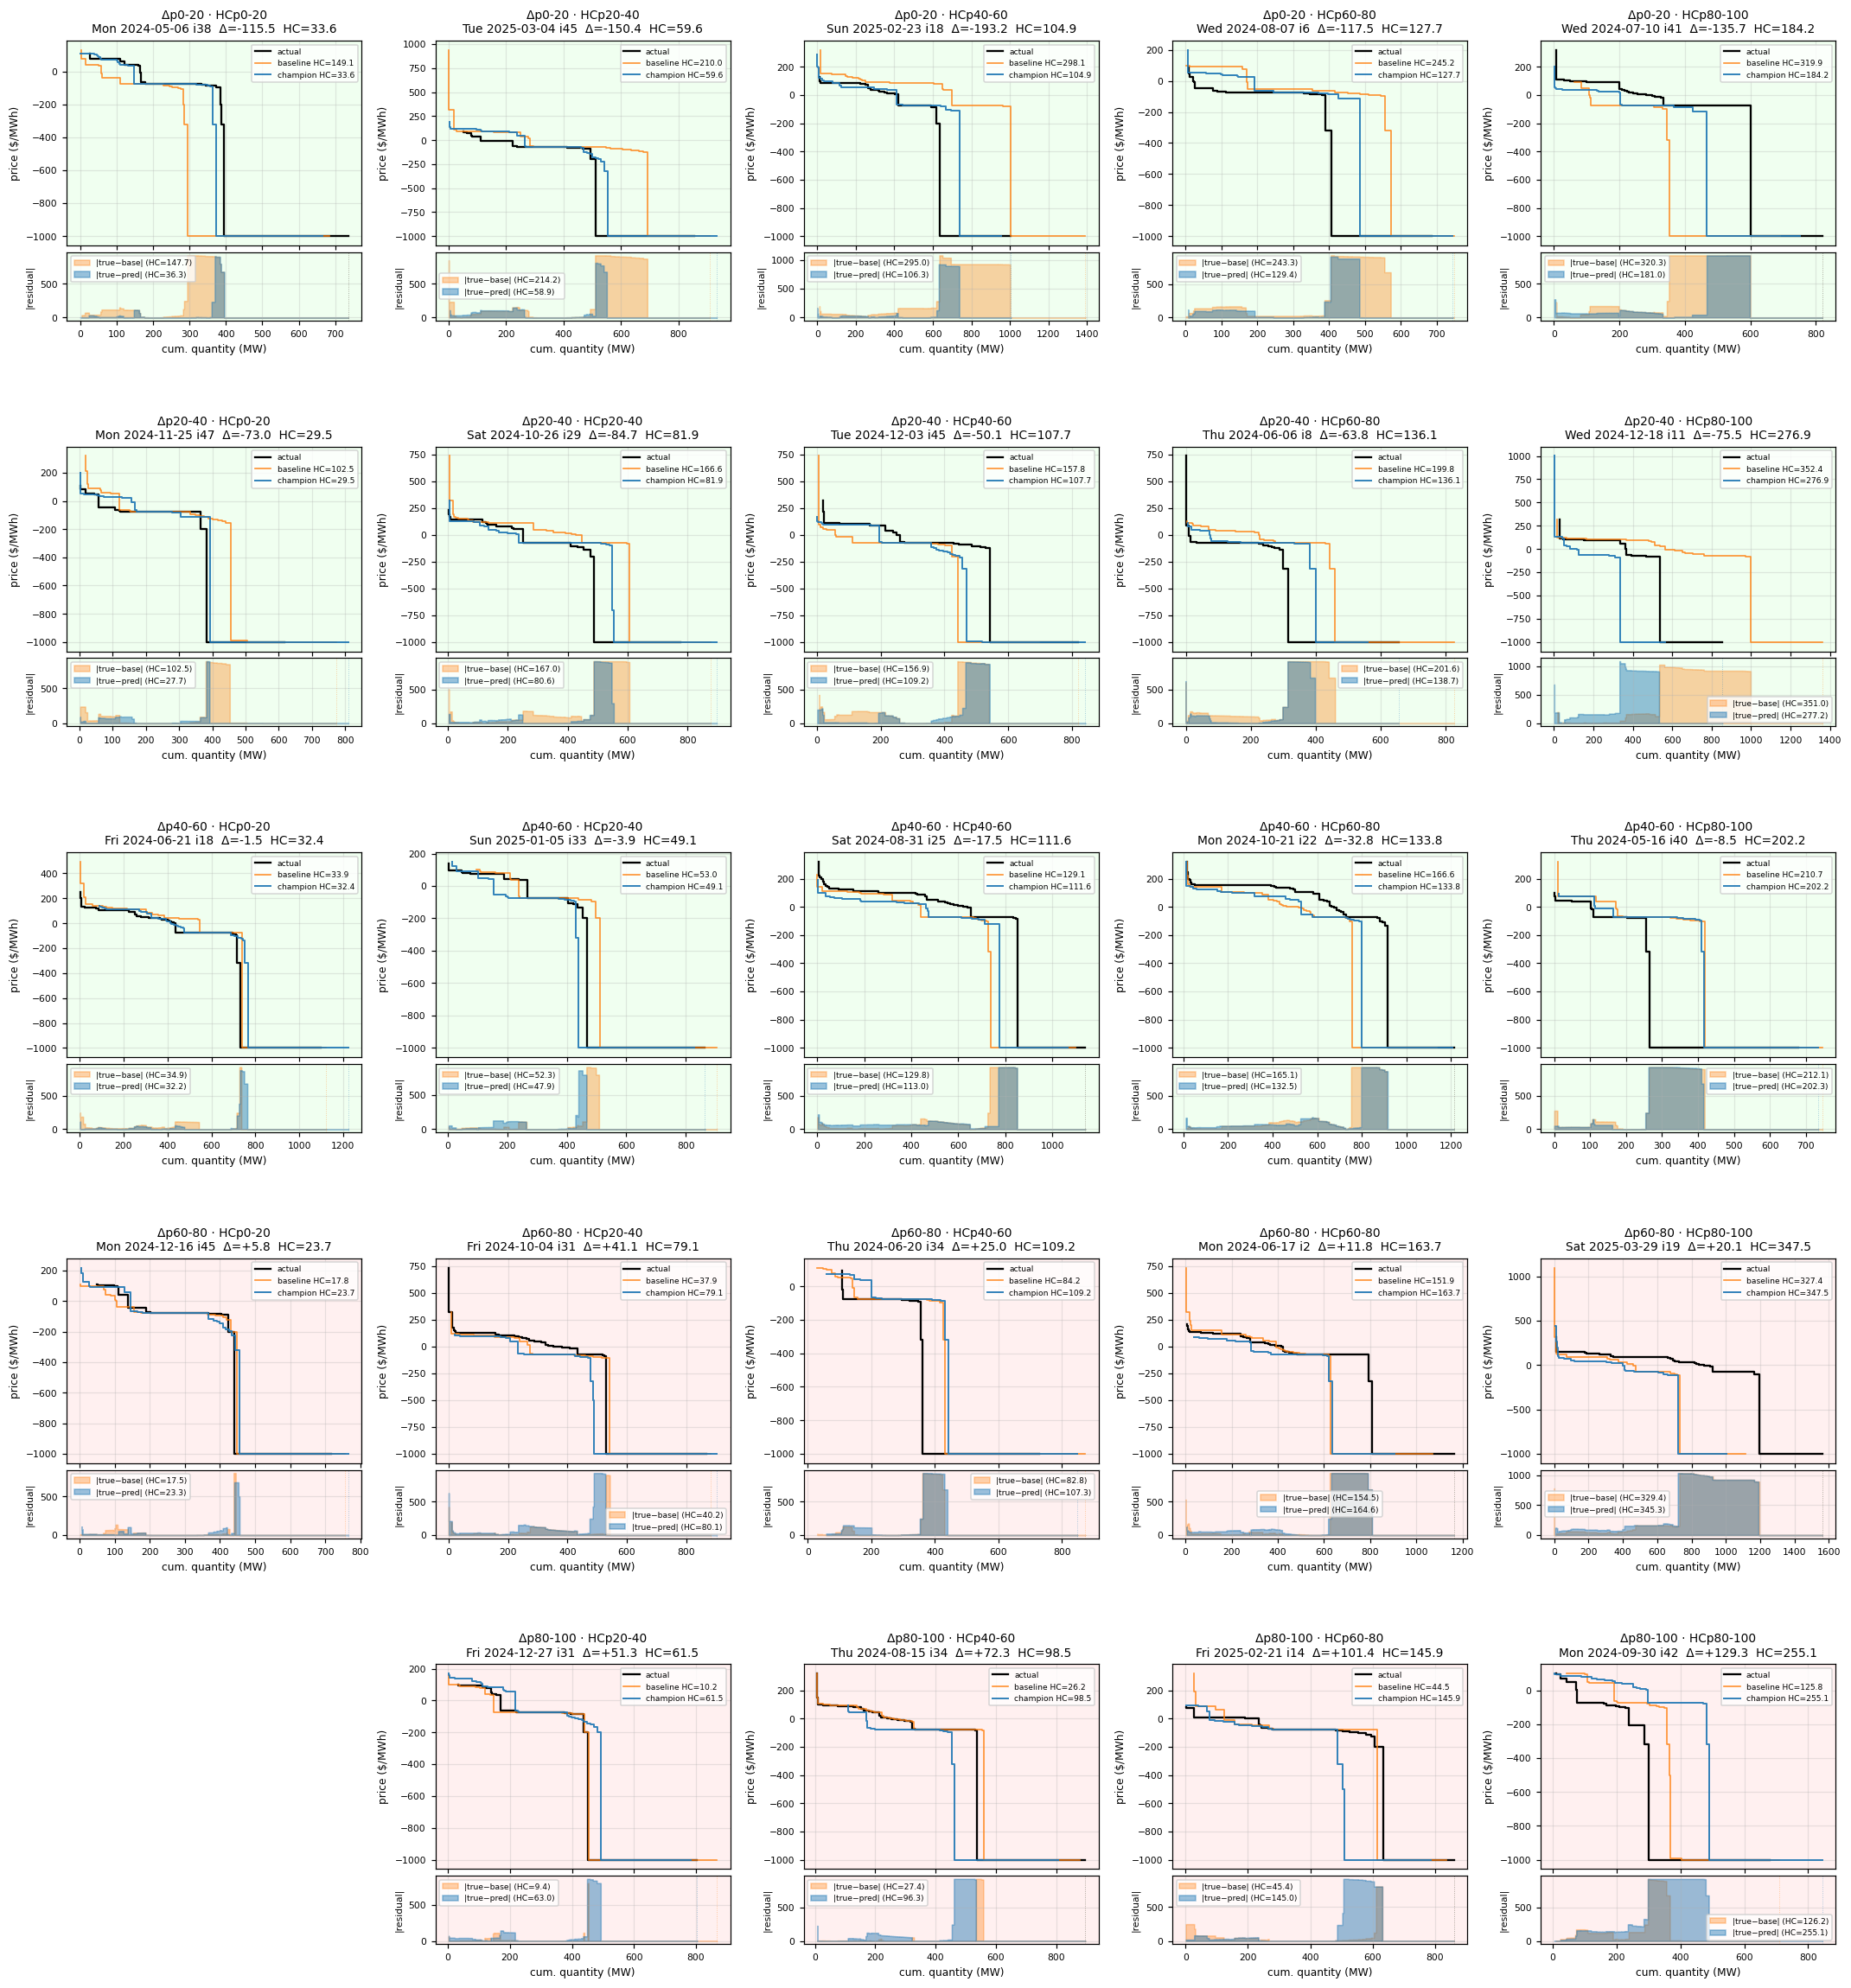

In [15]:
from matplotlib import gridspec
from aemo_curves.metrics.hc_mae import _step_eval

N_BINS_2D_R = 5
LIGHT_GREEN_R = '#f0fff0'
LIGHT_RED_R   = '#fff0f0'
RES_GRID_POINTS = 256

if 'delta_q' not in m.columns:
    m['delta_q'] = pd.qcut(m['delta_hc'], N_BINS_2D_R, labels=False, duplicates='drop')
    m['hc_q']    = pd.qcut(m['hc_mae'],   N_BINS_2D_R, labels=False, duplicates='drop')

rng_r = np.random.default_rng()

fig = plt.figure(figsize=(24, 26))
outer = gridspec.GridSpec(N_BINS_2D_R, N_BINS_2D_R, figure=fig,
                          hspace=0.45, wspace=0.25)
for row in range(N_BINS_2D_R):
    for col in range(N_BINS_2D_R):
        cell_df = m[(m['delta_q'] == row) & (m['hc_q'] == col)]
        inner = gridspec.GridSpecFromSubplotSpec(
            2, 1, subplot_spec=outer[row, col],
            height_ratios=[3, 1], hspace=0.05,
        )
        ax_top = fig.add_subplot(inner[0])
        ax_bot = fig.add_subplot(inner[1], sharex=ax_top)
        if len(cell_df) == 0:
            ax_top.set_visible(False); ax_bot.set_visible(False)
            continue
        r = cell_df.sample(1, random_state=rng_r.integers(1_000_000)).iloc[0]
        bg = LIGHT_GREEN_R if r['delta_hc'] < 0 else LIGHT_RED_R
        ax_top.set_facecolor(bg); ax_bot.set_facecolor(bg)

        # --- top: curves
        tq = np.asarray(r['true_curve_qty'], dtype=float)
        tp = np.asarray(r['true_curve_price'], dtype=float)
        bq = np.asarray(r['base_curve_qty'], dtype=float)
        bp = np.asarray(r['base_curve_price'], dtype=float)
        pq = np.asarray(r['pred_curve_qty'], dtype=float)
        pp = np.asarray(r['pred_curve_price'], dtype=float)
        ax_top.step(tq, tp, where='pre', color='black', lw=1.5, label='actual')
        ax_top.step(bq, bp, where='pre', color='C1', lw=1.1, alpha=0.85,
                    label=f'baseline HC={r["baseline_hc_mae"]:.1f}')
        ax_top.step(pq, pp, where='pre', color='C0', lw=1.3, alpha=0.9,
                    label=f'champion HC={r["hc_mae"]:.1f}')
        date_str = pd.Timestamp(r['Trading Date']).strftime('%a %Y-%m-%d')
        dlo, dhi = row * 20, (row + 1) * 20
        hlo, hhi = col * 20, (col + 1) * 20
        ax_top.set_title(f'Δp{dlo}-{dhi} · HCp{hlo}-{hhi}\n'
                         f'{date_str} i{int(r["Interval Number"])}  '
                         f'Δ={r["delta_hc"]:+.1f}  HC={r["hc_mae"]:.1f}',
                         fontsize=9)
        ax_top.set_ylabel('price ($/MWh)', fontsize=8)
        ax_top.tick_params(labelbottom=False, labelsize=7)
        ax_top.legend(fontsize=6, loc='best')

        # --- bottom: per-pair residual strips. HC-MAE uses pair-specific union
        #     support (see metrics/hc_mae.py:72-76), so each method gets its own
        #     V-grid. Mean of each shaded area equals the reported HC-MAE.
        v_min_b = float(min(tq.min(), bq.min()))
        v_max_b = float(max(tq.max(), bq.max()))
        v_min_p = float(min(tq.min(), pq.min()))
        v_max_p = float(max(tq.max(), pq.max()))
        if v_max_b <= v_min_b or v_max_p <= v_min_p:
            ax_bot.set_visible(False); continue
        vg_b = np.linspace(v_min_b, v_max_b, RES_GRID_POINTS)
        vg_p = np.linspace(v_min_p, v_max_p, RES_GRID_POINTS)
        res_base = np.abs(_step_eval(tq, tp, vg_b) - _step_eval(bq, bp, vg_b))
        res_pred = np.abs(_step_eval(tq, tp, vg_p) - _step_eval(pq, pp, vg_p))
        ax_bot.fill_between(vg_b, 0, res_base, color='C1', alpha=0.35, step='pre',
                            label=f'|true−base| (HC={res_base.mean():.1f})')
        ax_bot.fill_between(vg_p, 0, res_pred, color='C0', alpha=0.45, step='pre',
                            label=f'|true−pred| (HC={res_pred.mean():.1f})')
        # Mark each pair's V_max so the support difference is visible
        ax_bot.axvline(v_max_b, color='C1', lw=0.6, alpha=0.4, ls=':')
        ax_bot.axvline(v_max_p, color='C0', lw=0.6, alpha=0.4, ls=':')
        ax_bot.set_xlabel('cum. quantity (MW)', fontsize=8)
        ax_bot.set_ylabel('|residual|', fontsize=7)
        ax_bot.tick_params(labelsize=7)
        ax_bot.legend(fontsize=6, loc='best')

plt.show()

## 15. Outlier digging — top-20 worst rows by HC-MAE

Are the worst rows concentrated in particular dates / months / weekdays / intervals?

In [16]:
worst = m.nlargest(50, 'hc_mae').copy()
worst['weekday'] = worst['Trading Date'].dt.day_name()
print('Top-20 worst rows by champion HC-MAE:')
print(worst[['Trading Date', 'Interval Number', 'weekday', 'hc_mae',
             'baseline_hc_mae', 'delta_hc', 'true_total_mw']].head(20).round(2).to_string(index=False))

print('\nConcentration of top-50 worst rows:')
print('  by weekday:', worst['weekday'].value_counts().to_dict())
print('  by month:  ', worst['month'].value_counts().to_dict())
print('  by interval (top 10):', dict(worst['Interval Number'].value_counts().head(10)))

Top-20 worst rows by champion HC-MAE:
Trading Date  Interval Number   weekday  hc_mae  baseline_hc_mae  delta_hc  true_total_mw
  2024-06-15                9  Saturday  674.05           660.02     14.03         477.99
  2024-06-15                8  Saturday  652.25           652.38     -0.13         493.73
  2024-05-19                8    Sunday  643.96           542.79    101.18         462.66
  2025-03-09               10    Sunday  620.48           557.05     63.43         450.99
  2024-09-14                4  Saturday  606.85           528.81     78.05         446.76
  2025-01-28               12   Tuesday  606.82           371.61    235.20         900.85
  2024-09-14                5  Saturday  602.66           563.65     39.01         450.09
  2025-01-21                8   Tuesday  601.88           664.83    -62.95        1510.97
  2025-01-21               10   Tuesday  590.50           668.43    -77.93        1513.06
  2025-01-21               11   Tuesday  587.56           660.

## 16. Numerical summary

In [17]:
def stats(s):
    return {
        'n':      int(s.notna().sum()),
        'mean':   float(s.mean()),
        'median': float(s.median()),
        'p25':    float(s.quantile(0.25)),
        'p75':    float(s.quantile(0.75)),
        'p95':    float(s.quantile(0.95)),
        'std':    float(s.std()),
    }


summary = pd.DataFrame({
    'baseline lag-7':  stats(m['baseline_hc_mae']),
    'champion':        stats(m['hc_mae']),
    'Δ (champion-base)': stats(m['delta_hc']),
}).T
print('HC-MAE summary (all values $/MWh):')
print(summary.round(3).to_string())
print()
print(f'Win rate (champion < baseline per row): {m["win"].mean():.1%}')
print(f'Median Δ: {m["delta_hc"].median():+.3f}')
print(f'p25 / p75 Δ: {m["delta_hc"].quantile(0.25):+.3f} / {m["delta_hc"].quantile(0.75):+.3f}')

HC-MAE summary (all values $/MWh):
                         n     mean   median     p25      p75      p95      std
baseline lag-7     17232.0  148.969  121.923  63.830  206.954  366.433  110.463
champion           17232.0  123.410  100.927  57.161  164.455  304.307   90.067
Δ (champion-base)  17232.0  -25.558  -19.997 -78.580   30.450  115.451   95.190

Win rate (champion < baseline per row): 60.3%
Median Δ: -19.997
p25 / p75 Δ: -78.580 / +30.450
